## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [4]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [5]:
#!rm SUSY.csv

In [6]:
#!gunzip SUSY.csv.gz

In [7]:
ls -lh

total 6079256
drwxr-xr-x  3 sudeeppaul  staff    96B Oct 22 15:24 anaconda_projects/
-rw-r--r--  1 sudeeppaul  staff   357K Oct  9 14:34 Lab.7.ipynb
-rw-r--r--  1 sudeeppaul  staff   149K Oct  9 14:34 Lab.7.pdf
-rw-r--r--  1 sudeeppaul  staff   4.5M Oct 23 22:42 Lab.7.solution.ipynb
-rw-r--r--  1 sudeeppaul  staff   228M Oct 23 14:31 SUSY-small.csv
-rw-r--r--  1 sudeeppaul  staff   456M Oct  9 14:43 SUSY-small.csvhead
-rw-r--r--  1 sudeeppaul  staff   2.2G Oct  9 14:36 SUSY.csv


The data is provided as a comma separated file.

In [9]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [11]:
!ls -lh

total 6079256
drwxr-xr-x  3 sudeeppaul  staff    96B Oct 22 15:24 anaconda_projects
-rw-r--r--  1 sudeeppaul  staff   357K Oct  9 14:34 Lab.7.ipynb
-rw-r--r--  1 sudeeppaul  staff   149K Oct  9 14:34 Lab.7.pdf
-rw-r--r--  1 sudeeppaul  staff   4.5M Oct 23 22:42 Lab.7.solution.ipynb
-rw-r--r--  1 sudeeppaul  staff   228M Oct 23 14:31 SUSY-small.csv
-rw-r--r--  1 sudeeppaul  staff   456M Oct  9 14:43 SUSY-small.csvhead
-rw-r--r--  1 sudeeppaul  staff   2.2G Oct  9 14:36 SUSY.csv


We see that we have 5 million datapoints.

In [13]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [15]:
!head -500000 SUSY.csv > SUSY-small.csv

In [16]:
ls -lh

total 6104048
drwxr-xr-x  3 sudeeppaul  staff    96B Oct 22 15:24 anaconda_projects/
-rw-r--r--  1 sudeeppaul  staff   357K Oct  9 14:34 Lab.7.ipynb
-rw-r--r--  1 sudeeppaul  staff   149K Oct  9 14:34 Lab.7.pdf
-rw-r--r--  1 sudeeppaul  staff   4.5M Oct 23 22:42 Lab.7.solution.ipynb
-rw-r--r--  1 sudeeppaul  staff   228M Oct 23 22:43 SUSY-small.csv
-rw-r--r--  1 sudeeppaul  staff   456M Oct  9 14:43 SUSY-small.csvhead
-rw-r--r--  1 sudeeppaul  staff   2.2G Oct  9 14:36 SUSY.csv


In [17]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [20]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [22]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [23]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [24]:
FeatureNames

['R',
 'M_Delta_R',
 'M_R',
 'M_TR_2',
 'dPhi_r_b',
 'S_R',
 'cos_theta_r1',
 'MET_rel',
 'MT2',
 'axial_MET']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [26]:
%pip install pandas
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

You should consider upgrading via the '/Users/sudeeppaul/Desktop/Claude_Practice/OpenAI Agents Memory/venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


Now we can read the data into a pandas dataframe:

In [28]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [30]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [32]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]

The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


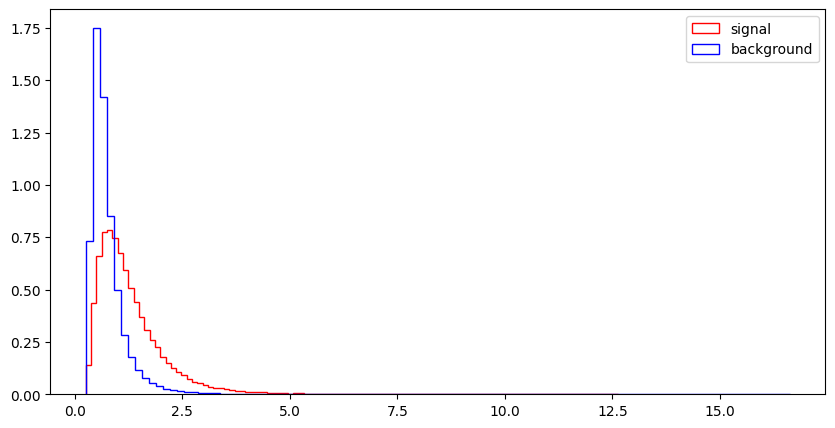

l_1_eta


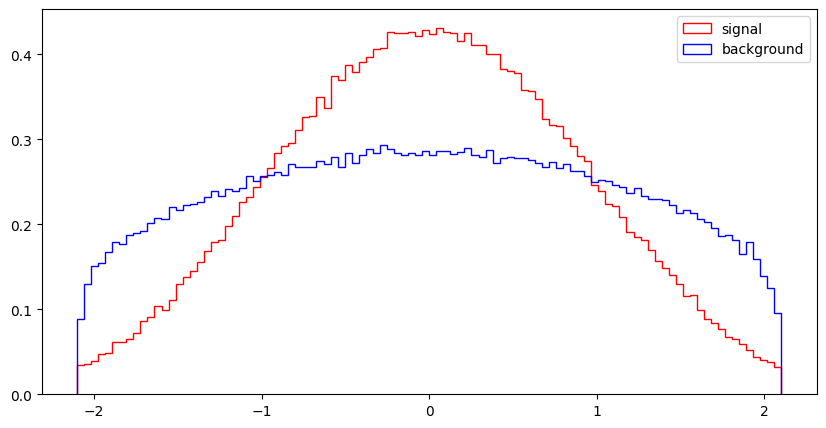

l_1_phi


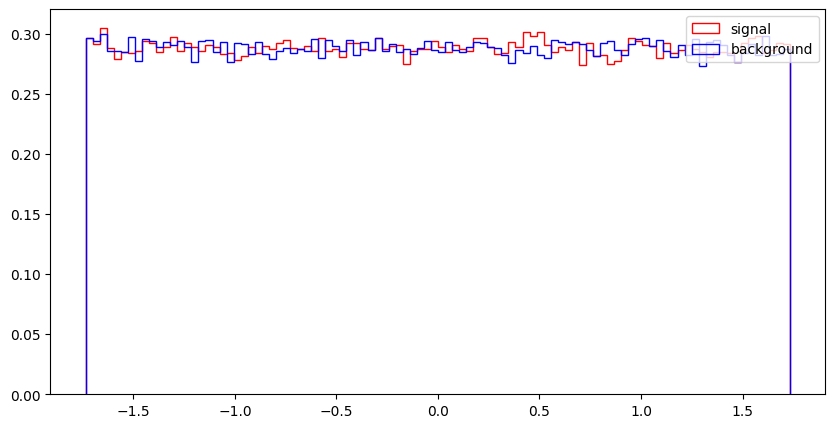

l_2_pT


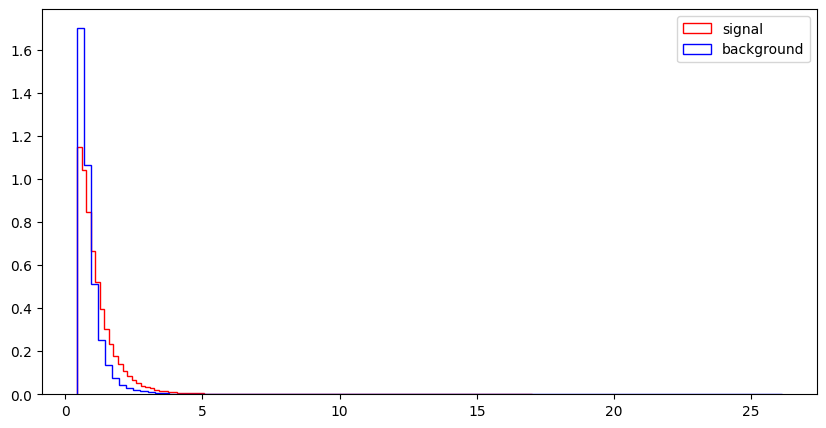

l_2_eta


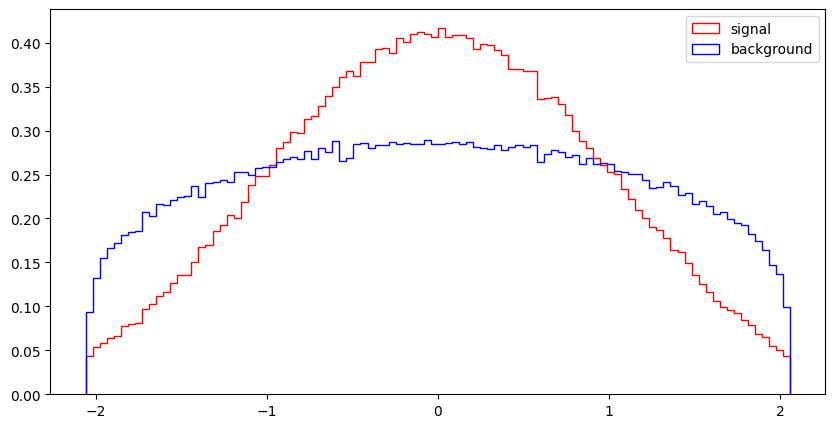

l_2_phi


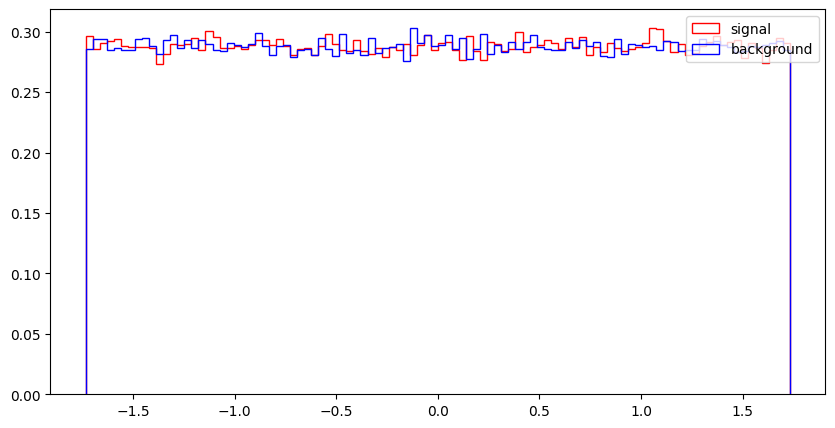

MET


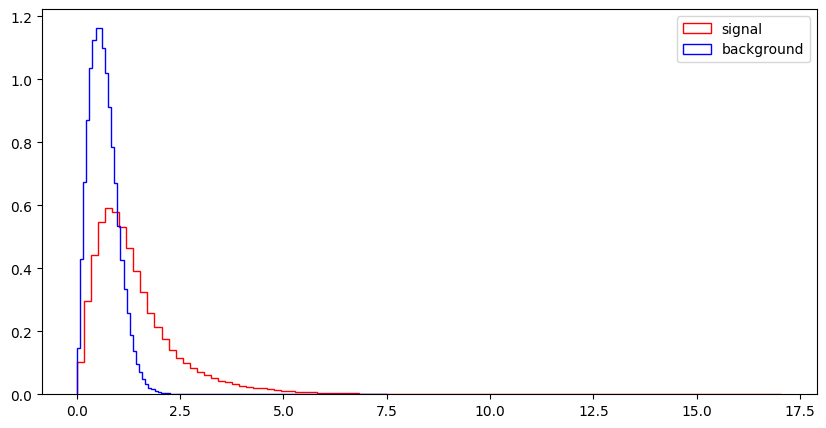

MET_phi


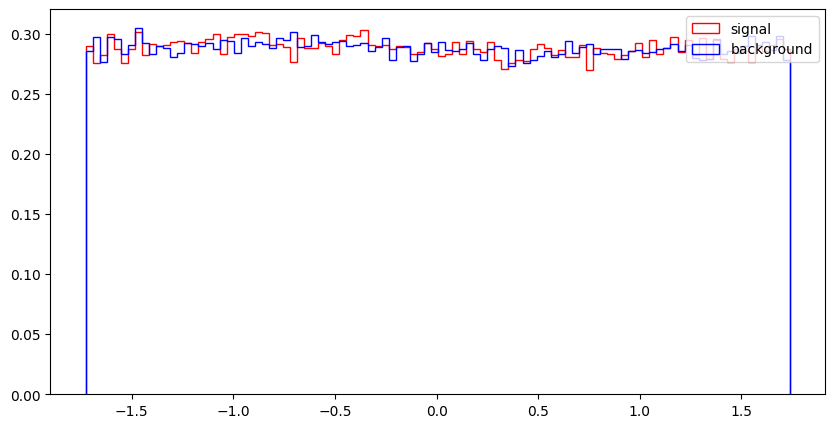

MET_rel


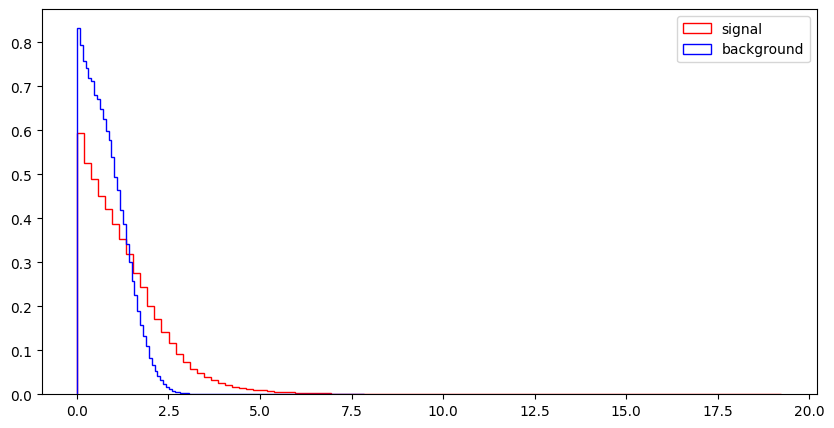

axial_MET


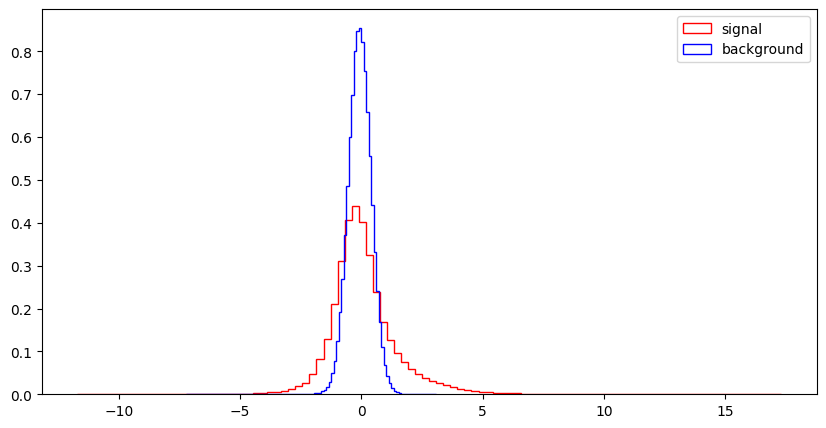

M_R


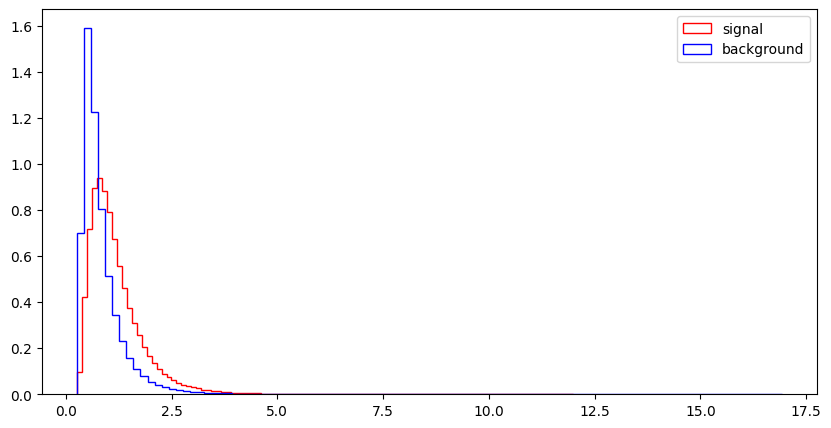

M_TR_2


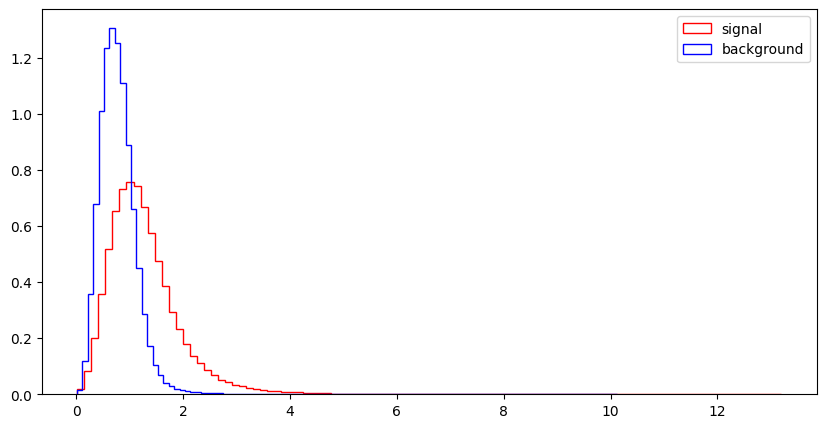

R


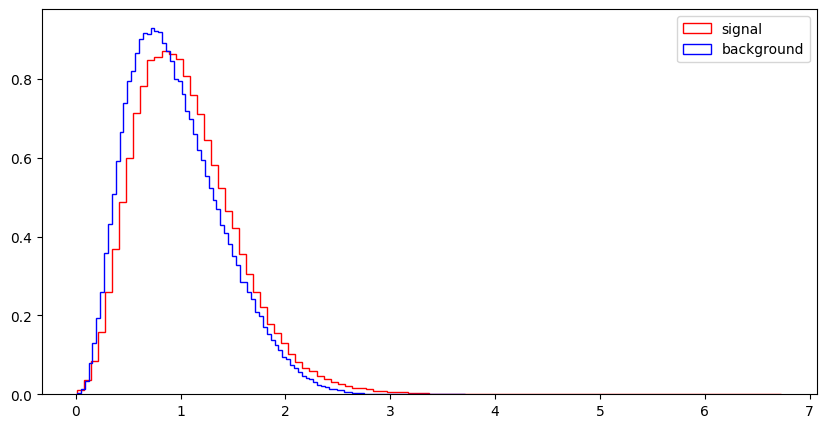

MT2


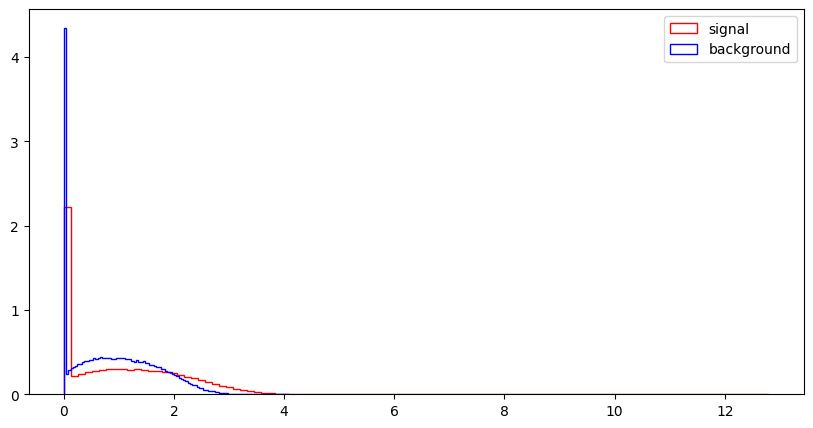

S_R


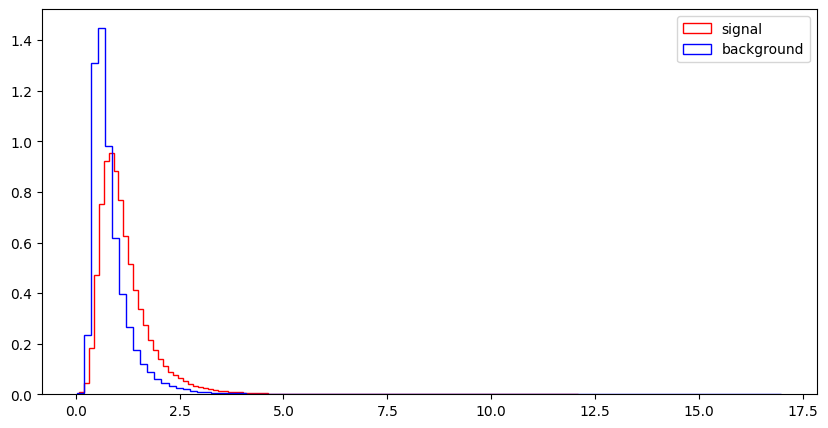

M_Delta_R


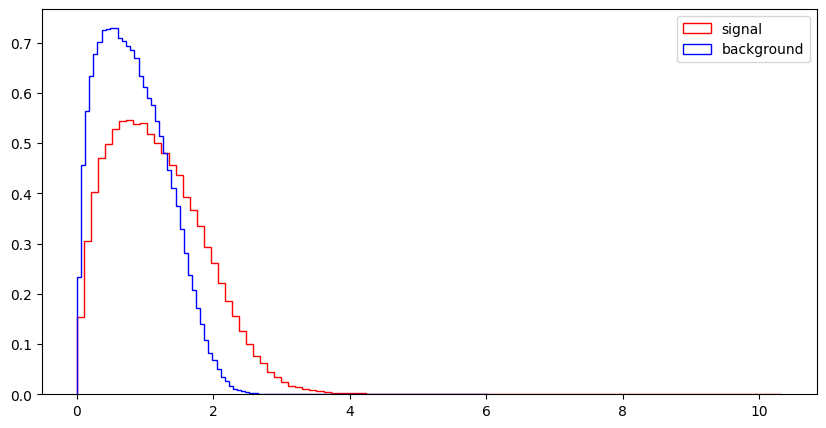

dPhi_r_b


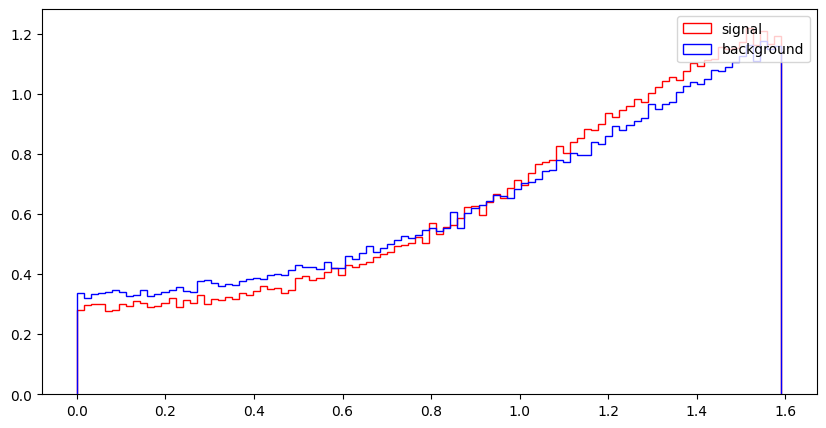

cos_theta_r1


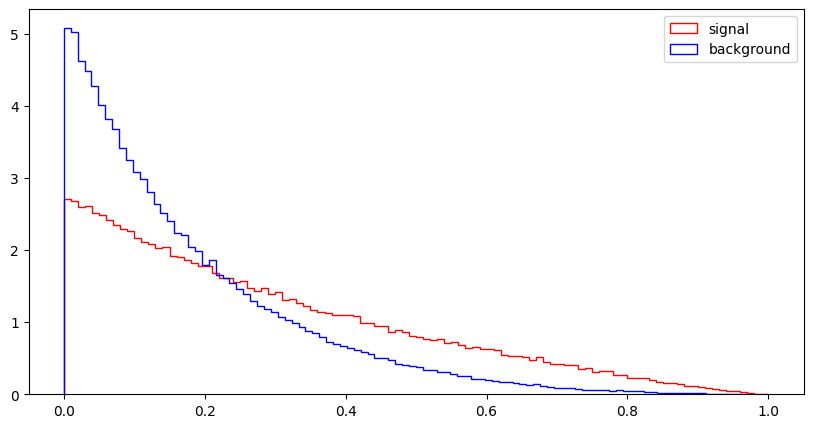

In [34]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

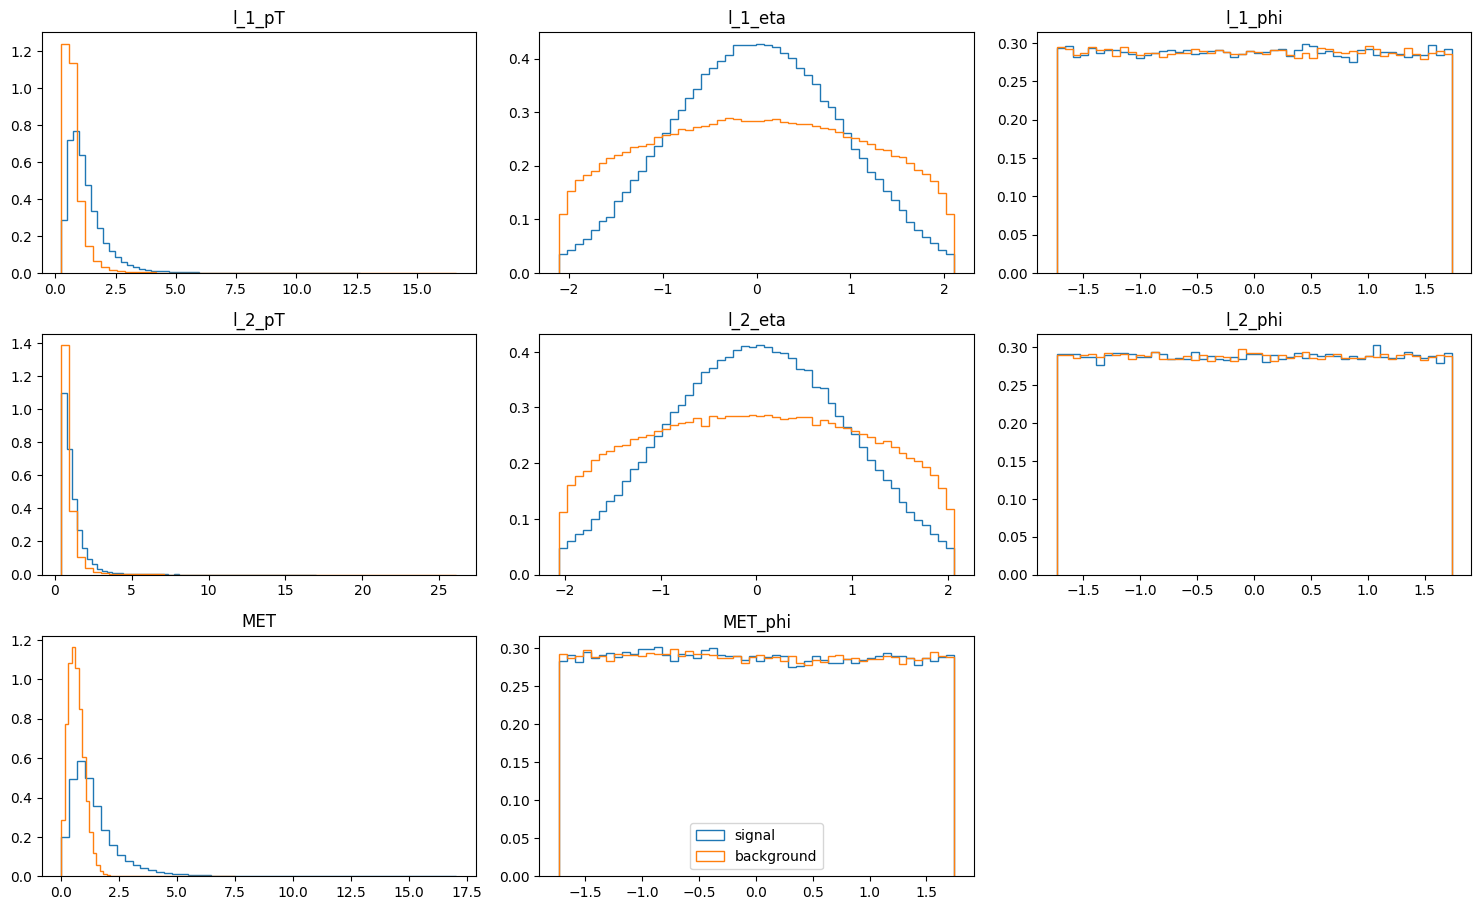

In [36]:
# Using the lecture notes, and past knowlege
# I came up with this 

low_level = VarNames[1:9]

plt.figure(figsize = (15, 15))

for i, var in enumerate(low_level):
    plt.subplot(5, 3, i + 1)

    plt.hist(
        np.array(df_sig[var]),bins = 50,
        histtype = "step",label = "signal",
        density = 1)

    plt.hist(
        np.array(df_bkg[var]),bins = 50,
        histtype = "step",label = "background",
        density = 1)

    plt.title(var)

plt.legend()
plt.tight_layout()
plt.show()

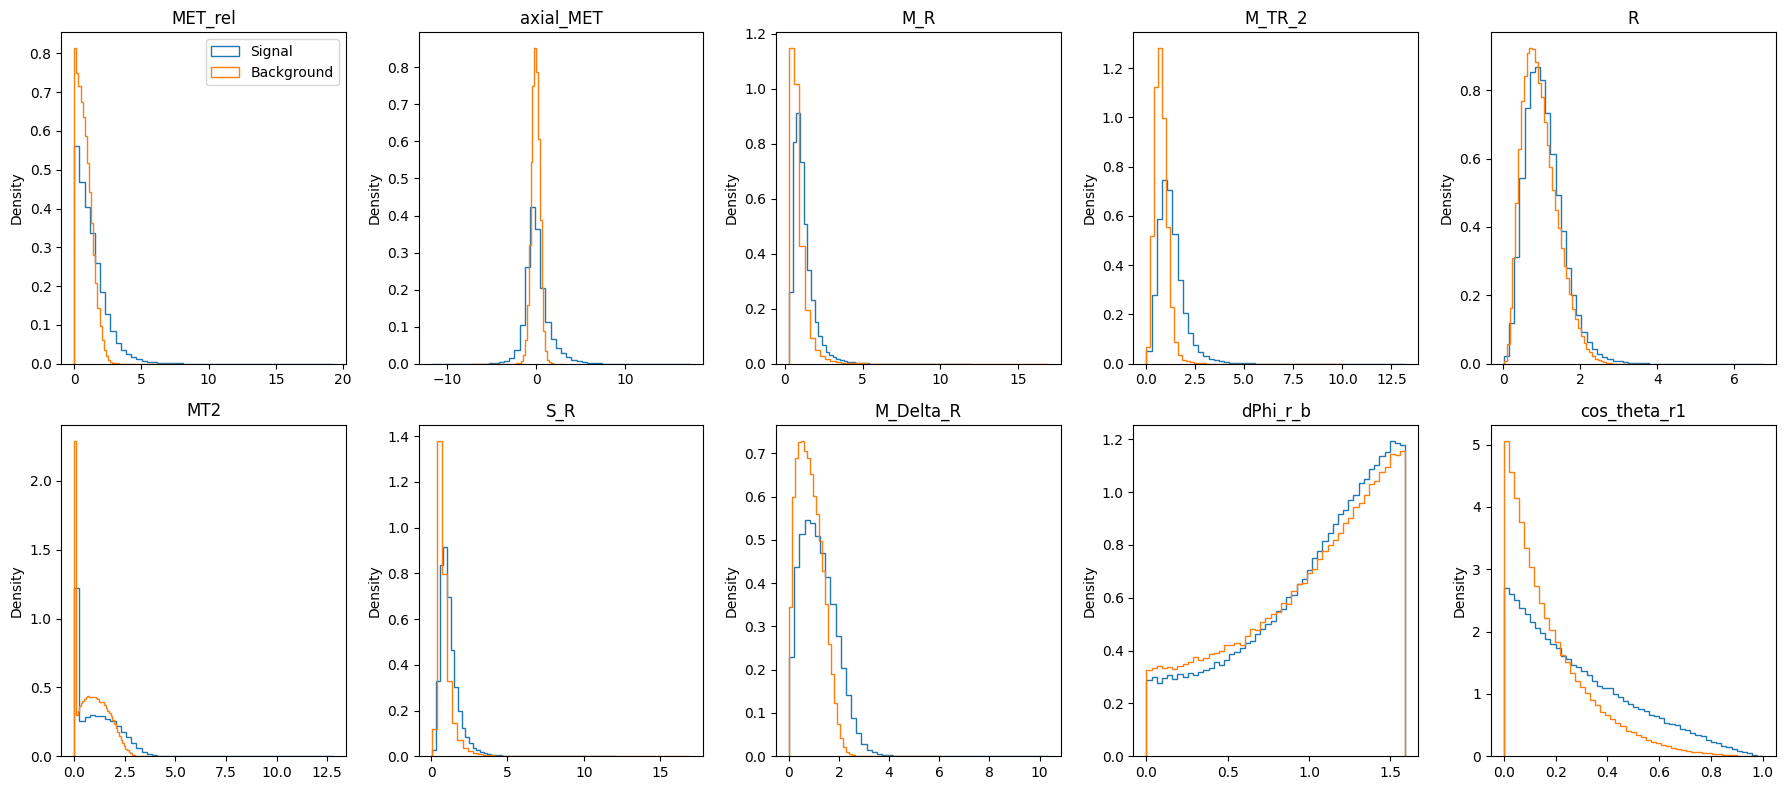

In [37]:
# Uisng the same method, all i did 
# was change the values of the size a bit
high_level = VarNames[9:]
fig, axes = plt.subplots(2, 5, figsize=(18, 8))

axes = axes.flatten()

for i, var in enumerate(high_level):

    axes[i].hist(np.array(df_sig[var]), bins = 50, 
                 histtype = "step", density = True, 
                 label = "Signal")

    axes[i].hist(np.array(df_bkg[var]), bins = 50, 
                 histtype = "step", density = True, 
                 label = "Background")

    axes[i].set_title(var)
    axes[i].set_ylabel("Density")

axes[0].legend()

plt.tight_layout()
plt.show()

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

In [39]:
# Part A
# I used a similar farming as within 
# the lecture but modified 
# some of the plots
def pair_plot(data_sig, data_bkg, columns):

    n_columns = len(columns)
    plt.figure(figsize = (15, 15))

    plot_i = 0

    for i, x_var_name in enumerate(columns):
        for j, y_var_name in enumerate(columns):

            plot_i += 1

            plt.subplot(n_columns, n_columns, plot_i)

            if i == j:

                plt.hist(data_sig[x_var_name], bins = 50,
                         histtype = "step", density = True,
                         label = "Signal")

                plt.hist(data_bkg[x_var_name], bins = 50,
                         histtype = "step", density = True,
                         label = "Background")

            else:

                plt.scatter(data_sig[x_var_name], data_sig[y_var_name],
                            s = 1, alpha = 0.2)

                plt.scatter(data_bkg[x_var_name], data_bkg[y_var_name],
                            s = 1, alpha = 0.2)

    plt.tight_layout()
    plt.show()


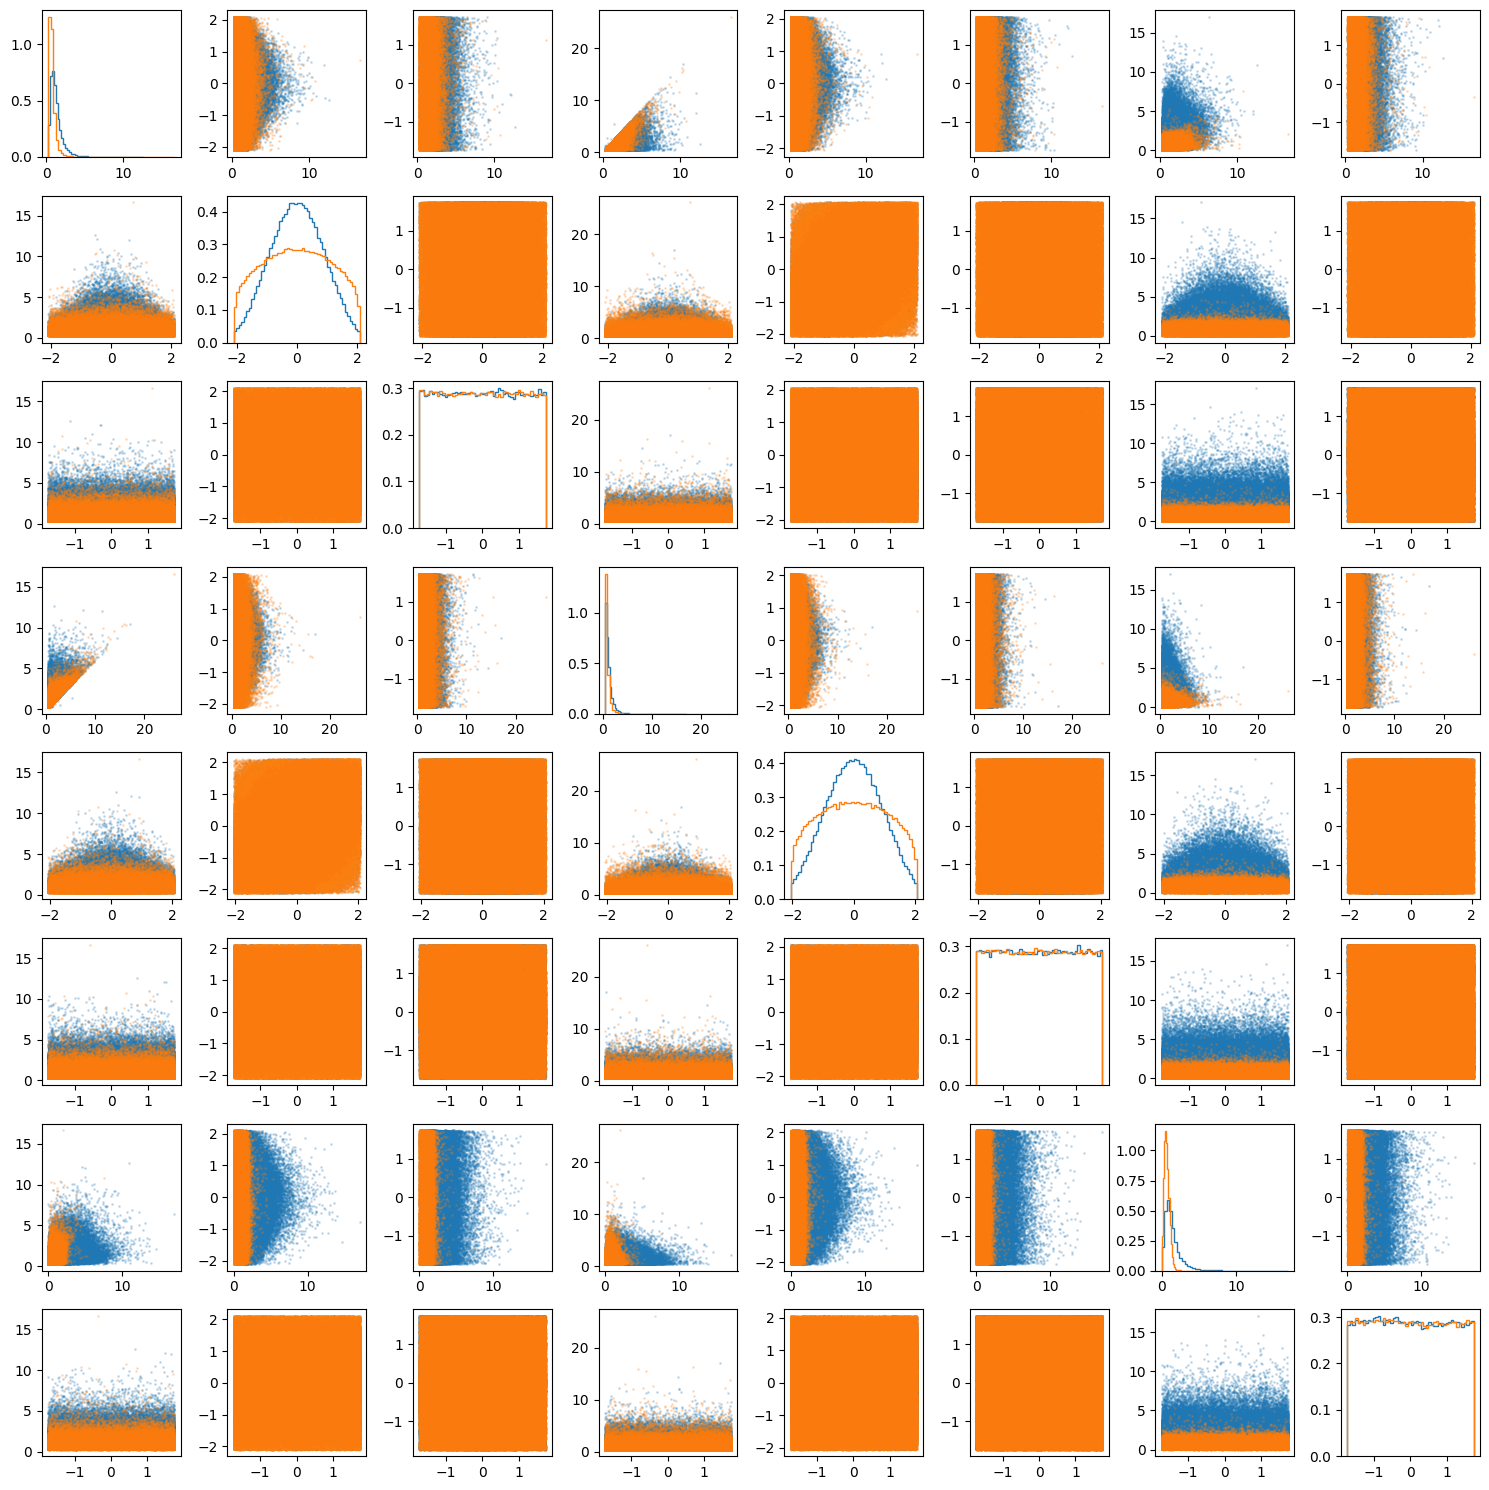

In [40]:
# TEsts for part A, low level
pair_plot(df_sig, df_bkg, low_level)

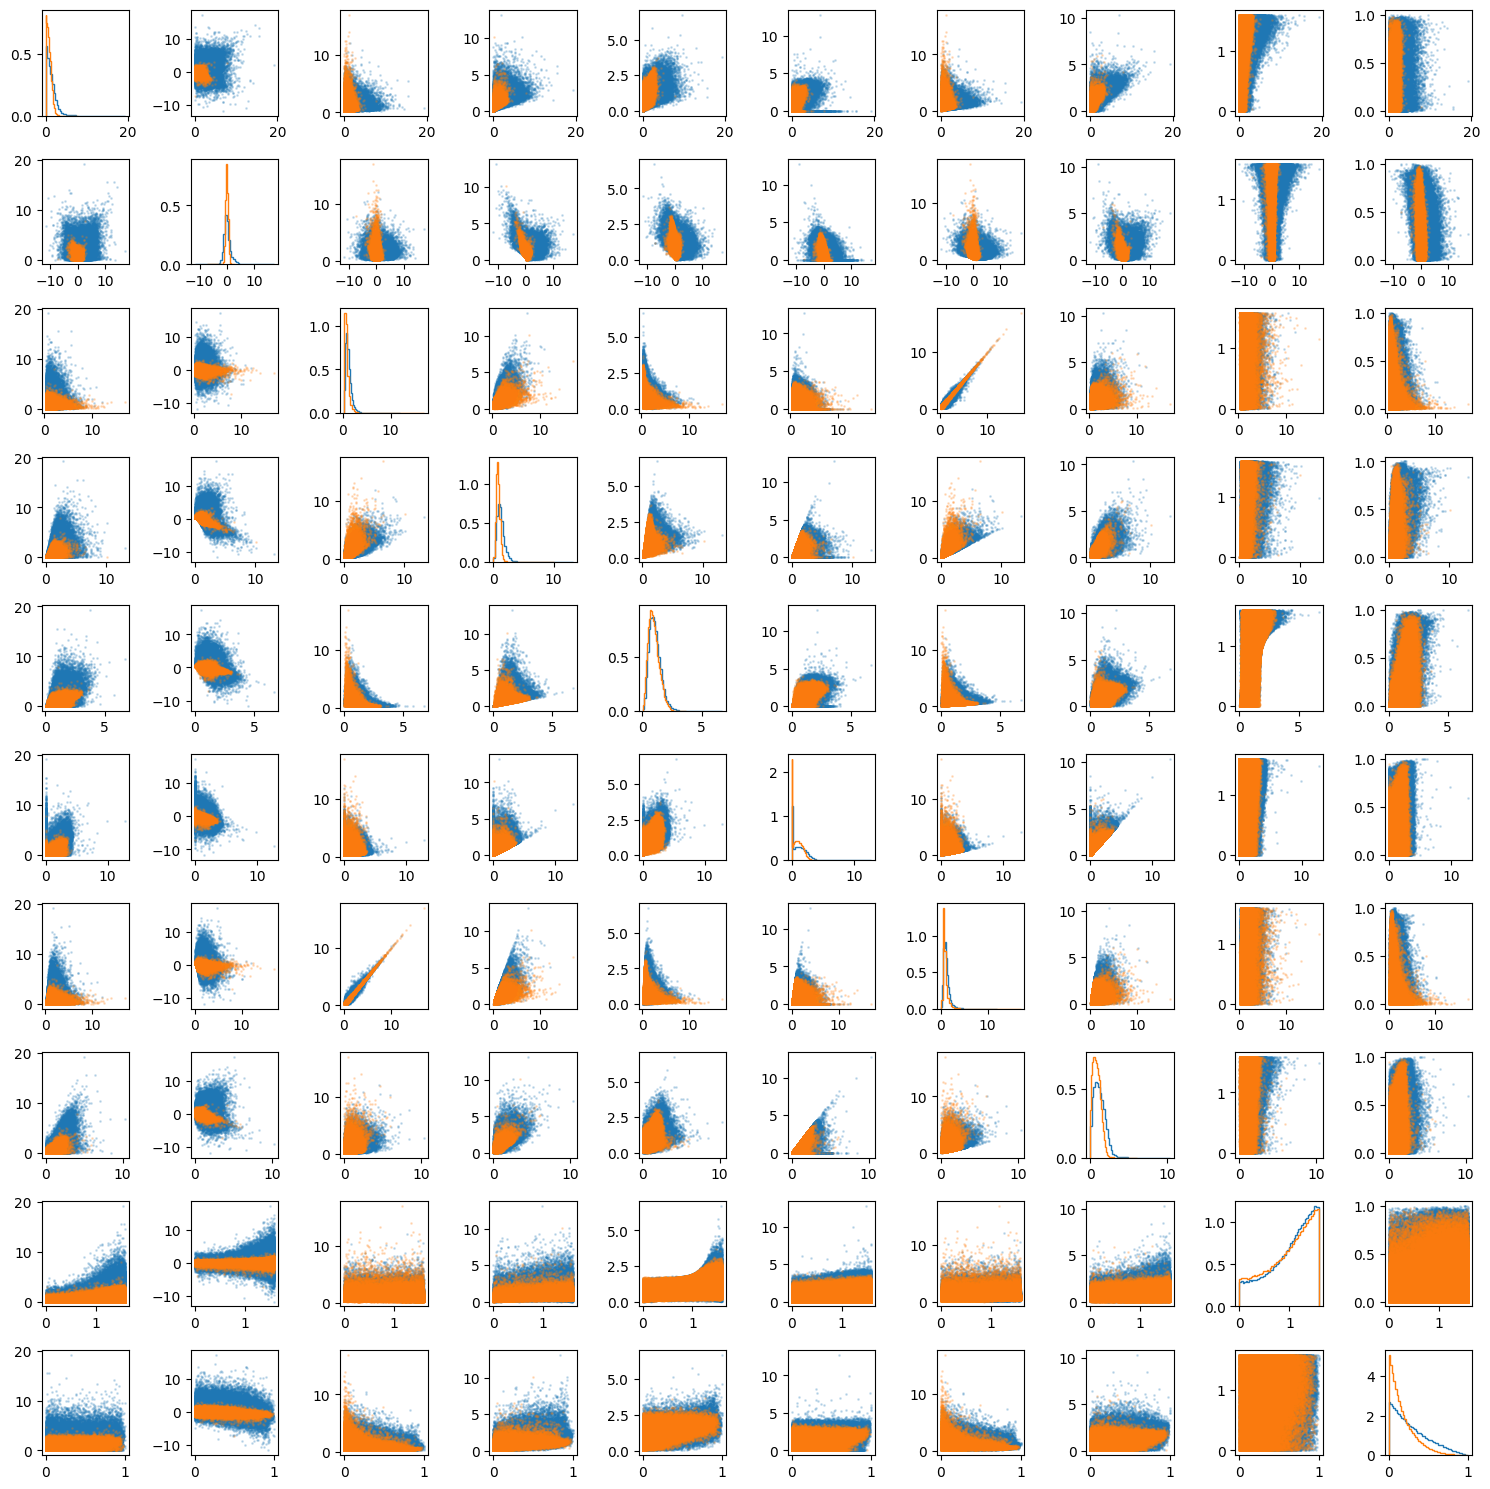

In [41]:
# Tests for part A, high level
pair_plot(df_sig, df_bkg, high_level)

In [42]:
#Part B

def pair_plot(data_sig, data_bkg, columns):

    n_columns = len(columns)
    plt.figure(figsize = (15, 15))

    plot_i = 0

    # as of righ tnow, the data is going through the
    # entire dataset, so taking a small sample 
    # will help speed up the process, at least it should
    # we will test it soon, other than that,
    # the code is the same
    data_sig_small = data_sig.sample(5000)
    data_bkg_small = data_bkg.sample(5000)

    for i, x_var_name in enumerate(columns):
        for j, y_var_name in enumerate(columns):

            plot_i += 1

            plt.subplot(n_columns, n_columns, plot_i)

            if i == j:

                plt.hist(data_sig[x_var_name], bins = 50,
                         histtype = "step", density = True,
                         label = "Signal")

                plt.hist(data_bkg[x_var_name], bins = 50,
                         histtype = "step", density = True,
                         label = "Background")

            else:

                plt.scatter(data_sig_small[x_var_name], data_sig_small[y_var_name],
                            s = 1, alpha = 0.2)

                plt.scatter(data_bkg_small[x_var_name], data_bkg_small[y_var_name],
                            s = 1, alpha = 0.2)

    plt.tight_layout()
    plt.show()

As mentioned in the comments, in order to speed up the pair plot, I decided to use a smaller smaple of data instead. All I did was cap it at 5000. This means the program loops over less data and makes it much faster to plot. 

Anoterh way we can use to speed up the pair plot would be to caulaute the historam bins and use those values intead. This makes it so that the histograms are not reculting each time, so it should make the plots faster in loaded. Kind of like how cache works. 

Part C:

Out of the observations, though it was hard to indetify them, I think the best one that I saw the best difference was the l_1_pT and l_2_pT plot, om the low-level. On the other hand, for the high-level, MET_rel, M_TR_2 and MT2 graphs are helpful. They habe seperation beyween singla and the bakground, which I was able to notice. 

### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

In [46]:
# 4.2 part a, 
%pip install tabulate

You should consider upgrading via the '/Users/sudeeppaul/Desktop/Claude_Practice/OpenAI Agents Memory/venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


Hint: Example code for embedding a `tabulate` table into a notebook:

In [48]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [49]:
# 4.3 part b
# for the sake of this problem, 
# I will beusing .cov() and .corrcoef
# from numpy

#it seems like we need to find
# this for the low data, high data, and
# all of it 

all_data = np.array(df[VarNames[1:]])

low_data = np.array(df[low_level])

high_data = np.array(df[high_level])

# Noe we want to find the covarience of each
cov_low = np.cov(low_data, rowvar = False)
cov_high = np.cov(high_data, rowvar = False)
cov_all = np.cov(all_data, rowvar = False)

# Now we want to find the vorrelation matrix
corrcoef_low = np.corrcoef(low_data, rowvar = False)
corrcoef_high = np.corrcoef(high_data, rowvar = False)
corrcoef_all = np.corrcoef(all_data, rowvar = False)

In [50]:
print("Shape of the difference values:")

print("Low level covariance :", cov_low.shape)
print("Low level correlation :", corrcoef_low.shape)

print("High level covariance :", cov_high.shape)
print("High level correlation :", corrcoef_high.shape)

print("All covariance :", cov_all.shape)
print("All correlation :", corrcoef_all.shape)

Shape of the difference values:
Low level covariance : (8, 8)
Low level correlation : (8, 8)
High level covariance : (10, 10)
High level correlation : (10, 10)
All covariance : (18, 18)
All correlation : (18, 18)


In [51]:
# Now I want to work on 4.2 part C
# The method here create a table for eacj
#and then represent the tabulate
# i ued GPT to guide me on the implementation
# As ive never worked with tabelu before
# I fed it the question, and asked it to help me understand
# the logic and omplement the code for me 
# it seemed to jhave taken a simple approch and 
# the code  is very similar 

# What i leared: I learned how to set
# up a a clean matrix display for tableu

In [52]:
table = []

for i in range(len(low_level)):

    row = [low_level[i]]

    for value in corrcoef_low[i]:
        row.append(round(value, 3))

    table.append(row)

headers = ["Variable"] + list(low_level)

display(HTML(tabulate.tabulate(
    table,
    tablefmt = "html",
    headers = headers
)))

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


In [53]:
# Low level covariance table

table = []

for i in range(len(low_level)):

    row = [low_level[i]]

    for value in cov_low[i]:
        row.append(round(value, 3))

    table.append(row)

headers = ["Variable"] + list(low_level)

display(HTML(tabulate.tabulate(
    table,
    tablefmt = "html",
    headers = headers
)))

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


In [54]:
# High level correlation table

table = []

for i in range(len(high_level)):

    row = [high_level[i]]

    for value in corrcoef_high[i]:
        row.append(round(value, 3))

    table.append(row)

headers = ["Variable"] + list(high_level)

display(HTML(tabulate.tabulate(
    table,
    tablefmt = "html",
    headers = headers
)))

Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272
M_R,0.078,0.027,1,0.577,-0.383,-0.068,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1,0.38,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.38,1,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.068,0.379,0.574,1,-0.021,0.809,0.056,0.264
S_R,0.15,-0.067,0.981,0.635,-0.287,-0.021,1,0.249,-0.013,-0.085
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1,0.155,0.319
dPhi_r_b,0.378,-0.057,-0.106,0.229,0.424,0.056,-0.013,0.155,1,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.085,0.319,0.106,1


In [55]:
# High level covariance table

table = []

for i in range(len(high_level)):

    row = [high_level[i]]

    for value in cov_high[i]:
        row.append(round(value, 3))

    table.append(row)

headers = ["Variable"] + list(high_level)

display(HTML(tabulate.tabulate(
    table,
    tablefmt = "html",
    headers = headers
)))

Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.21,-0.113,-0.037,0.38,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.38,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.01
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.19,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.01,0.039,0.009,0.039


In [56]:
# All observable correlation table

all_variables = VarNames[1:]

table = []

for i in range(len(all_variables)):

    row = [all_variables[i]]

    for value in corrcoef_all[i]:
        row.append(round(value, 3))

    table.append(row)

headers = ["Variable"] + list(all_variables)

display(HTML(tabulate.tabulate(
    table,
    tablefmt = "html",
    headers = headers
)))

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


In [57]:
# All observable covariance table

table = []

for i in range(len(all_variables)):

    row = [all_variables[i]]

    for value in cov_all[i]:
        row.append(round(value, 3))

    table.append(row)

headers = ["Variable"] + list(all_variables)

display(HTML(tabulate.tabulate(
    table,
    tablefmt = "html",
    headers = headers
)))

Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,-0.01,0.364,0.287,-0.06,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0,0.001,0.001,0.001,0.001,0
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,-0.001,-0.001,0,0,0.001,-0.001,0.001,-0,0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0,0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.005,-0,-0.001,-0.001,-0,0,-0.002,-0.001,-0.002,0
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.01,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Here I learned how to use Tableu, and it seems like it ussined a similar format for each of the displays. I think this can be turned into a function, which the next part is going to help me with. ChatGPT as part of the other prompt, helped me with that part as well. 

In [59]:
# 4.2 part d
# Since the code above is repeated
# I can turn it into a function

def matrix_tables(data, variables):

    data = np.array(data[variables])

    covariance = np.cov(data, rowvar = False)
    correlation = np.corrcoef(data, rowvar = False)

    cov_table = []

    for i in range(len(variables)):

        row = [variables[i]]

        for value in covariance[i]:
            row.append(round(value, 3))

        cov_table.append(row)

    headers = ["Variable"] + list(variables)

    print("Covariance Matrix")

    display(HTML(tabulate.tabulate(
        cov_table,
        tablefmt = "html",
        headers = headers
    )))

    corr_table = []

    for i in range(len(variables)):

        row = [variables[i]]

        for value in correlation[i]:
            row.append(round(value, 3))

        corr_table.append(row)

    print("Correlation Matrix")

    display(HTML(tabulate.tabulate(
        corr_table,
        tablefmt = "html",
        headers = headers
    )))

In [60]:
# low level data 
matrix_tables(df, low_level)

Covariance Matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003


Correlation Matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1


In [61]:
# high level data 
matrix_tables(df, high_level)

Covariance Matrix


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054
M_R,0.044,0.017,0.392,0.21,-0.113,-0.037,0.38,0.074,-0.029,-0.014
M_TR_2,0.302,-0.185,0.21,0.338,0.104,0.189,0.228,0.242,0.058,0.052
R,0.249,-0.181,-0.113,0.104,0.222,0.232,-0.083,0.165,0.087,0.058
MT2,0.409,-0.461,-0.037,0.189,0.232,0.738,-0.011,0.433,0.021,0.045
S_R,0.082,-0.041,0.38,0.228,-0.083,-0.011,0.382,0.096,-0.003,-0.01
M_Delta_R,0.415,-0.233,0.074,0.242,0.165,0.433,0.096,0.389,0.042,0.039
dPhi_r_b,0.146,-0.025,-0.029,0.058,0.087,0.021,-0.003,0.042,0.19,0.009
cos_theta_r1,0.055,-0.054,-0.014,0.052,0.058,0.045,-0.01,0.039,0.009,0.039


Correlation Matrix


Variable,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
MET_rel,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272
M_R,0.078,0.027,1,0.577,-0.383,-0.068,0.981,0.189,-0.106,-0.116
M_TR_2,0.584,-0.317,0.577,1,0.38,0.379,0.635,0.668,0.229,0.451
R,0.595,-0.383,-0.383,0.38,1,0.574,-0.287,0.564,0.424,0.627
MT2,0.535,-0.535,-0.068,0.379,0.574,1,-0.021,0.809,0.056,0.264
S_R,0.15,-0.067,0.981,0.635,-0.287,-0.021,1,0.249,-0.013,-0.085
M_Delta_R,0.748,-0.373,0.189,0.668,0.564,0.809,0.249,1,0.155,0.319
dPhi_r_b,0.378,-0.057,-0.106,0.229,0.424,0.056,-0.013,0.155,1,0.106
cos_theta_r1,0.316,-0.272,-0.116,0.451,0.627,0.264,-0.085,0.319,0.106,1


In [62]:
# all the data
matrix_tables(df, VarNames[1:])

Covariance Matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.467,-0,0,0.305,-0,0.001,0.228,-0.001,0.098,-0.01,0.364,0.287,-0.06,-0.012,0.343,0.098,-0.047,0.022
l_1_eta,-0,1.004,-0.001,-0,0.408,-0.001,-0.002,-0.001,-0.001,-0.001,-0.001,-0.001,0,0,-0.001,-0.001,-0.001,0
l_1_phi,0,-0.001,1.004,0.001,0,-0.267,0.001,-0.185,0.001,-0.002,0.001,0.001,0,0.001,0.001,0.001,0.001,0
l_2_pT,0.305,-0,0.001,0.425,-0.001,0,0.079,-0.002,-0.001,0.051,0.325,0.163,-0.099,-0.069,0.322,0.006,-0.004,-0.028
l_2_eta,-0,0.408,0,-0.001,1.006,0,0,-0,0.001,-0.001,-0.001,0,0,0.001,-0.001,0.001,-0,0
l_2_phi,0.001,-0.001,-0.267,0,0,1.004,-0,-0.035,0.001,-0.002,0.001,0.001,0.001,0.002,0.001,0.001,-0,0
MET,0.228,-0.002,0.001,0.079,0,-0,0.762,-0.003,0.546,0.154,0.145,0.365,0.188,0.155,0.166,0.315,0.146,0.073
MET_phi,-0.001,-0.001,-0.185,-0.002,-0,-0.035,-0.003,1.003,-0.005,-0,-0.001,-0.001,-0,0,-0.002,-0.001,-0.002,0
MET_rel,0.098,-0.001,0.001,-0.001,0.001,0.001,0.546,-0.005,0.79,-0.12,0.044,0.302,0.249,0.409,0.082,0.415,0.146,0.055
axial_MET,-0.01,-0.001,-0.002,0.051,-0.001,-0.002,0.154,-0,-0.12,1.005,0.017,-0.185,-0.181,-0.461,-0.041,-0.233,-0.025,-0.054


Correlation Matrix


Variable,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,1,-0.001,0,0.684,-0.001,0.001,0.383,-0.001,0.16,-0.014,0.851,0.723,-0.186,-0.021,0.811,0.229,-0.157,0.165
l_1_eta,-0.001,1,-0.001,-0,0.406,-0.001,-0.002,-0.001,-0.002,-0.001,-0.001,-0.001,0.001,0,-0.001,-0.002,-0.002,0.002
l_1_phi,0,-0.001,1,0.002,0,-0.266,0.001,-0.184,0.001,-0.002,0.002,0.001,0,0.001,0.002,0.001,0.002,0.001
l_2_pT,0.684,-0,0.002,1,-0.001,0,0.14,-0.002,-0.001,0.078,0.797,0.43,-0.324,-0.123,0.799,0.014,-0.013,-0.217
l_2_eta,-0.001,0.406,0,-0.001,1,0,0,-0,0.001,-0.001,-0.001,0,0.001,0.002,-0.001,0.001,-0.001,0.001
l_2_phi,0.001,-0.001,-0.266,0,0,1,-0,-0.035,0.002,-0.002,0.001,0.001,0.001,0.003,0.001,0.002,-0.001,0
MET,0.383,-0.002,0.001,0.14,0,-0,1,-0.003,0.704,0.176,0.264,0.72,0.457,0.206,0.307,0.579,0.383,0.425
MET_phi,-0.001,-0.001,-0.184,-0.002,-0,-0.035,-0.003,1,-0.005,-0,-0.002,-0.002,-0,0,-0.003,-0.001,-0.004,0.001
MET_rel,0.16,-0.002,0.001,-0.001,0.001,0.002,0.704,-0.005,1,-0.134,0.078,0.584,0.595,0.535,0.15,0.748,0.378,0.316
axial_MET,-0.014,-0.001,-0.002,0.078,-0.001,-0.002,0.176,-0,-0.134,1,0.027,-0.317,-0.383,-0.535,-0.067,-0.373,-0.057,-0.272


What I elarned: I leanred how to combine reapting functions into one function; however it handles diffenr data. The function essentially takes datasets and varibles as arguemtns and caualutes the variences. Then it displays both on a on a table. This makes the code more intutaive and allows the same function for differnt levels of obsevations. 

## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

Exercise 5.1 
For this exercise, I looked at the ditrubutions for Exercise 3. The labels that I will prsent are from the headers of those tables. I classified them babsed on the signal vs bakground obersvation. Varibles such as MET, M_TR_2, and M_Delta_R are more x > xc as the signal are higher than the background values. 

Exericse 5.2 (REPSONSE)

For this exericse, I did not know
how to proceed with the exerise
so I asked ChatGPT to guide me

I the prompt was:
 Hwere is the prompts for exercise 5
 can you help me think through this 
 problem and help me with the coding aspec tof it
 Asusme that I am new to this occnepts, so 
explain it to me in that way. 
 use a similar coding style to what I typically use
 so i can undersatnd teh variables and keep it 
 simple but accurate

 Here are the results I got from the 
 GPT

 here is what I learned:
 I learned that TPR is the 
percentage of signal events that pass a selection cut, 
while FPR is the percentage of background events that 
also pass that same cut.

I also learned that the direction of the cut depends on the distribution of the variable. For example, if signal events tend to have larger values than background events, I can use x > xc. If signal tends to have smaller values, I can use x < xc.

I_1_eta and I_2_eta are digrams taht show more concentation in the center, which measn that the it leans more towar the |x- mew| < xc.

On the otehr had, you can see the bagkround is more concentrated around |x - mew| > xc for axial_MET. I would use those for the data going forward. 

In [67]:
def get_efficiency(data, cut, selection):

    if selection == ">":
        passed = np.sum(data > cut)

    elif selection == "<":
        passed = np.sum(data < cut)

    return passed / len(data)

In [68]:
def plot_efficiency(var, selection):

    signal = np.array(df_sig[var])
    background = np.array(df_bkg[var])

    cuts = np.linspace(
        min(signal.min(), background.min()),
        max(signal.max(), background.max()),
        100
    )

    signal_eff = []
    background_eff = []

    for cut in cuts:

        signal_eff.append(get_efficiency(signal, cut, selection))
        background_eff.append(get_efficiency(background, cut, selection))

    plt.plot(cuts, signal_eff, label = "Signal Efficiency")
    plt.plot(cuts, background_eff, label = "Background Efficiency")

    plt.xlabel("Cut Value")
    plt.ylabel("Efficiency")
    plt.title(var)

    plt.legend()
    plt.show()

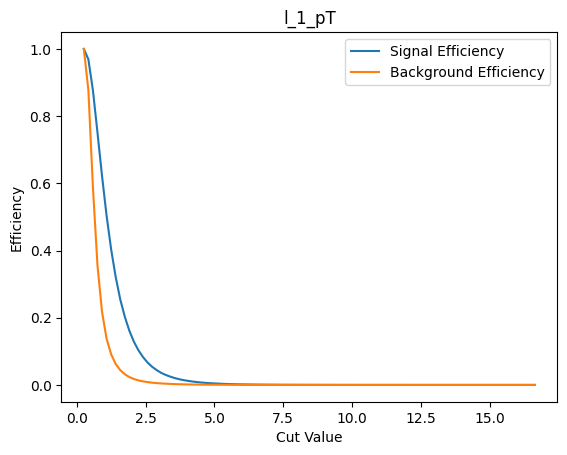

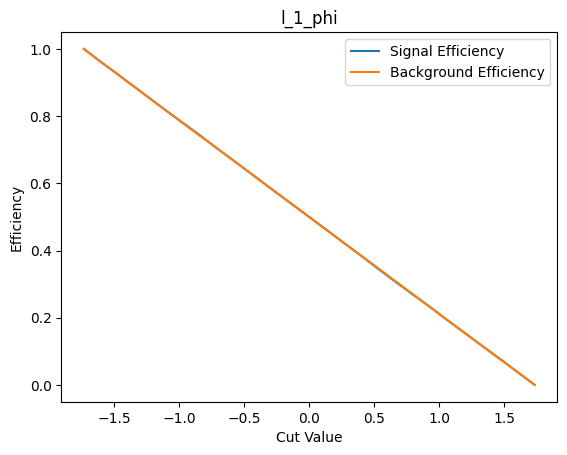

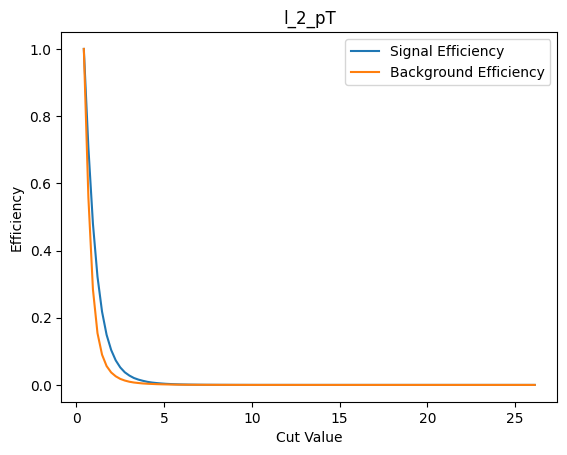

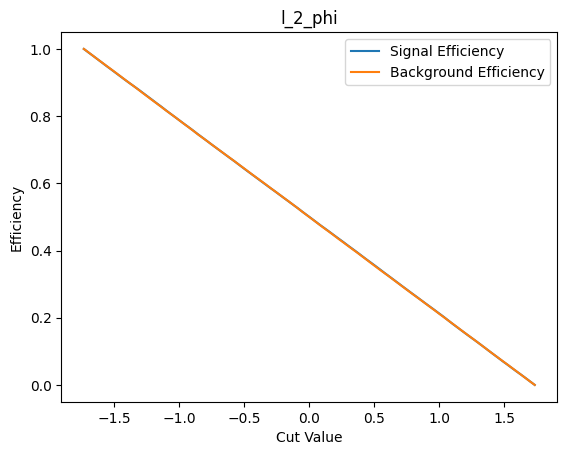

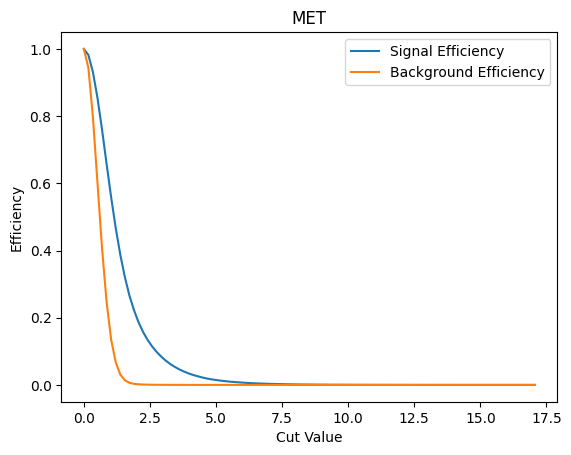

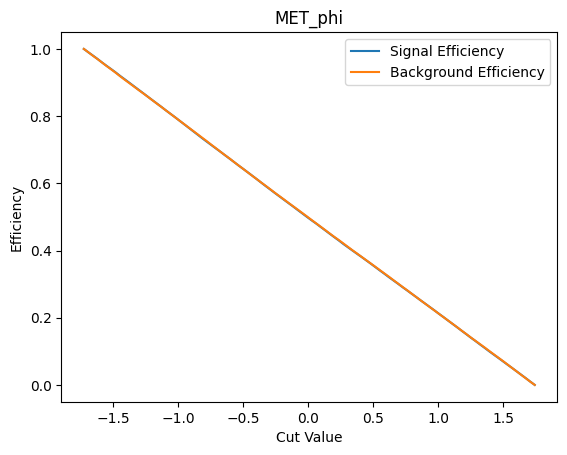

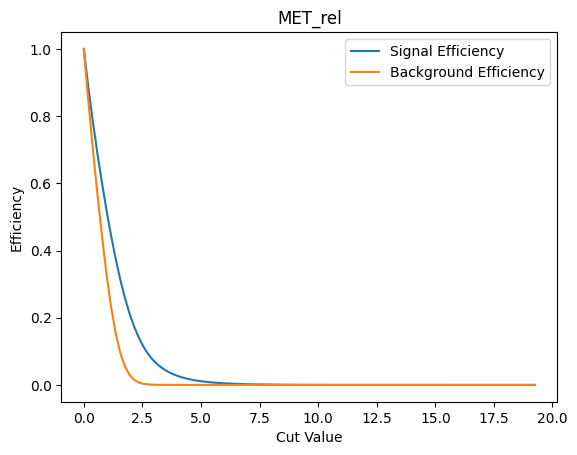

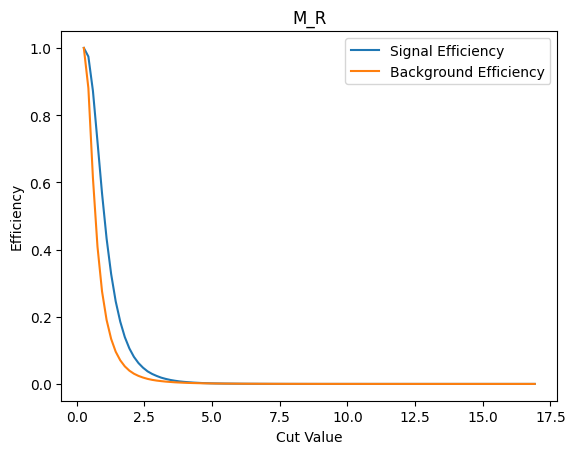

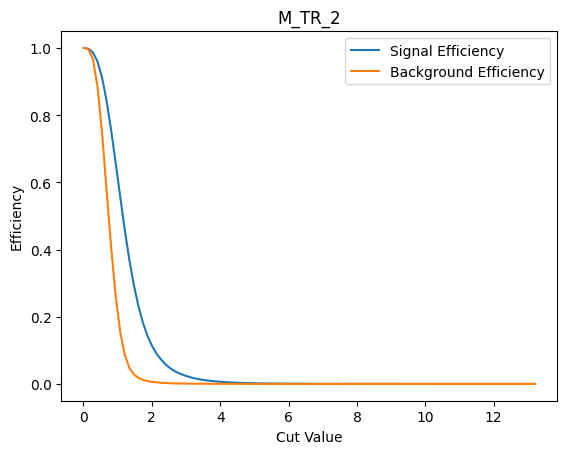

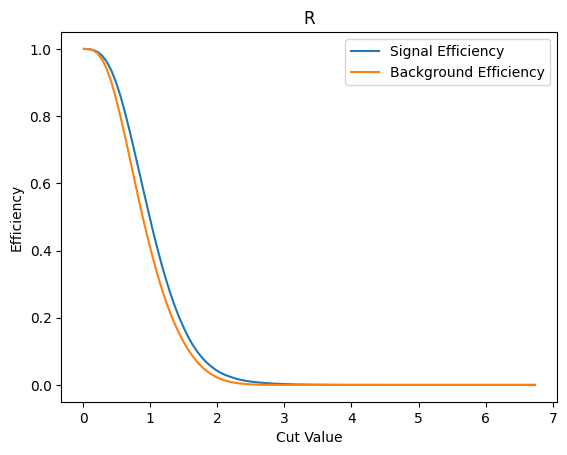

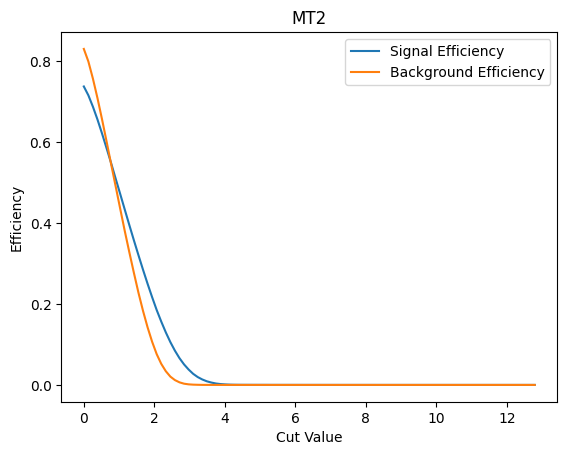

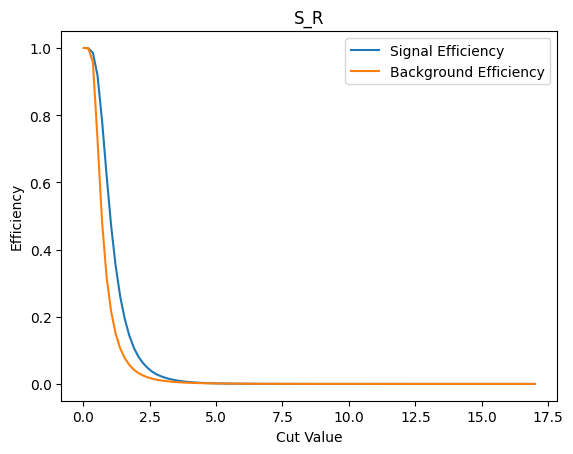

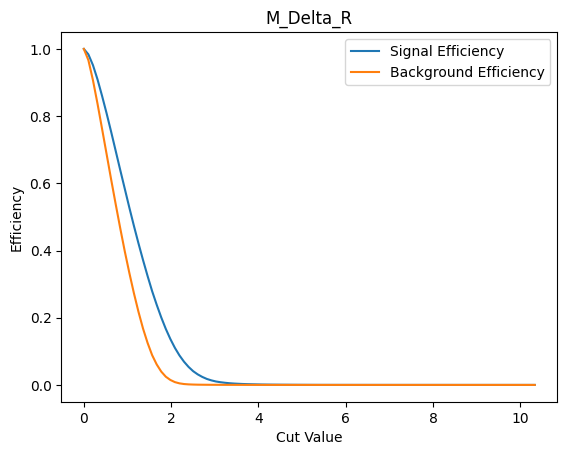

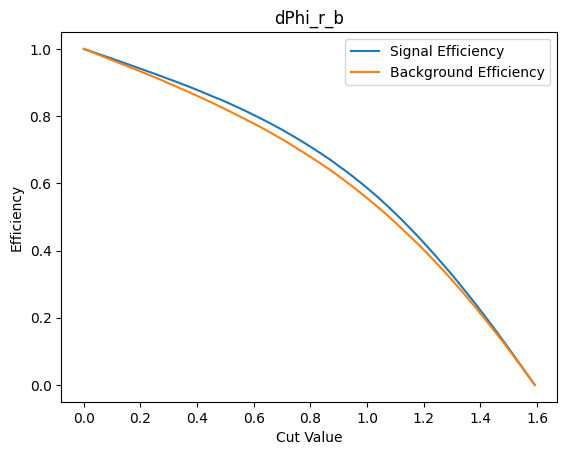

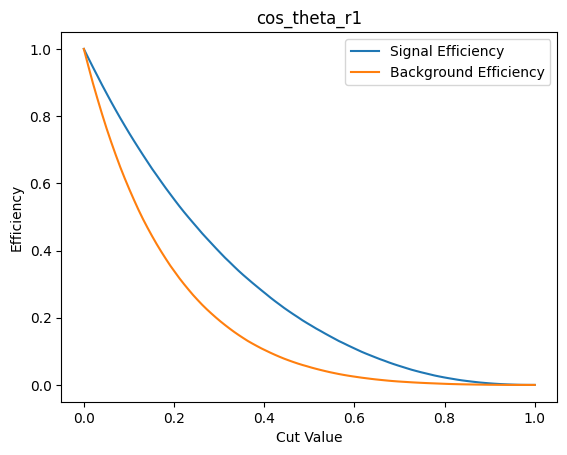

In [69]:
for var in VarNames[1:]:

    if var in ["l_1_eta", "l_2_eta", "axial_MET"]:
        continue

    plot_efficiency(var, ">")

In [70]:
# Exercise 5.3 

def plot_significance(var, selection, NS, NB):

    signal = np.array(df_sig[var])
    background = np.array(df_bkg[var])

    cuts = np.linspace(
        min(signal.min(), background.min()),
        max(signal.max(), background.max()),
        100
    )

    significance = []

    for cut in cuts:

        signal_eff = get_efficiency(signal, cut, selection)
        background_eff = get_efficiency(background, cut, selection)

        new_signal = signal_eff * NS
        new_background = background_eff * NB

        if new_signal + new_background > 0:
            sigma = new_signal / np.sqrt(new_signal + new_background)
        else:
            sigma = 0

        significance.append(sigma)

    best_index = np.argmax(significance)

    print("Best cut:", cuts[best_index])
    print("Best significance:", significance[best_index])

    plt.plot(cuts, significance)

    plt.xlabel("Cut Value")
    plt.ylabel("Significance")
    plt.title(var)

    plt.show()

Best cut: 0.9171981320838736
Best significance: 1.1760913764900565


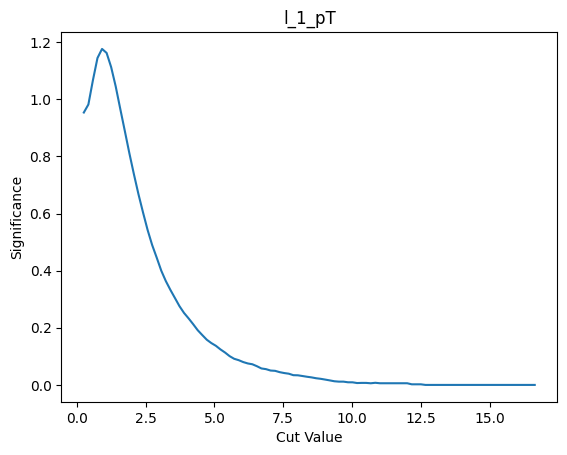

Best cut: 0.9171981320838736
Best significance: 3.719127486191184


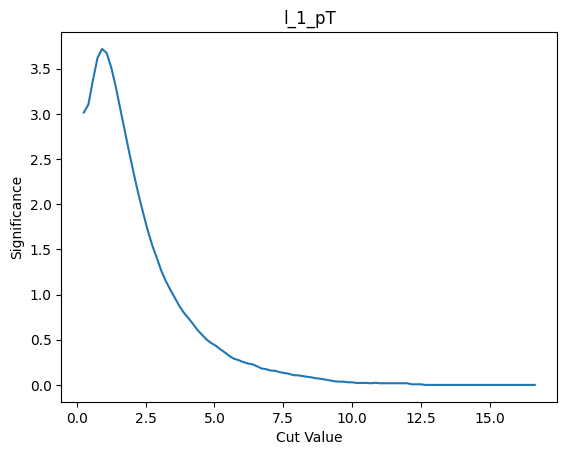

Best cut: 0.9171981320838736
Best significance: 11.760913764900563


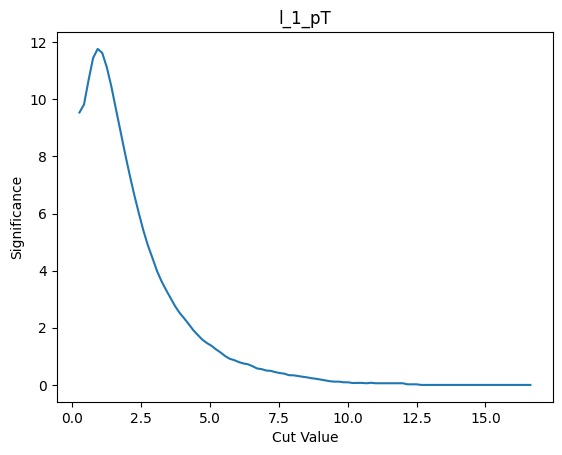

Best cut: 0.9171981320838736
Best significance: 37.19127486191184


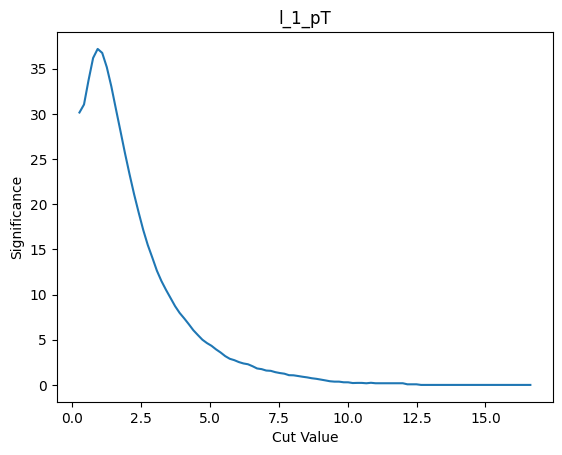

Best cut: -1.7347718477249143
Best significance: 0.9534641899295221


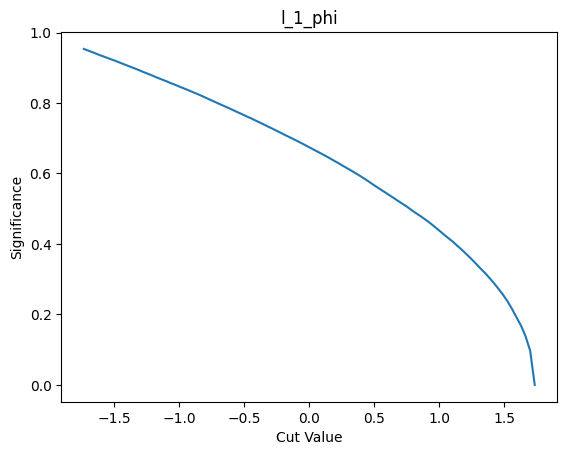

Best cut: -1.7347718477249143
Best significance: 3.015118507584668


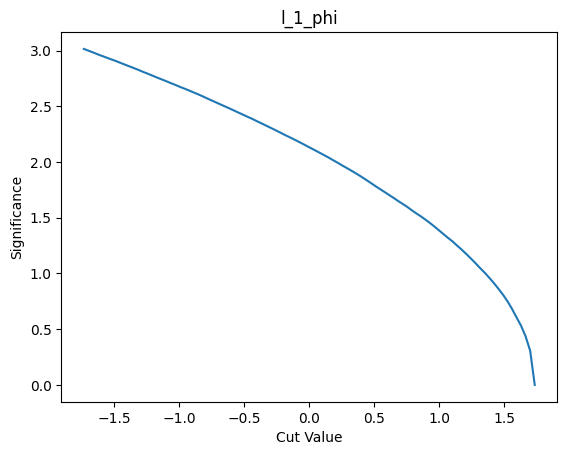

Best cut: -1.7347718477249143
Best significance: 9.534641899295222


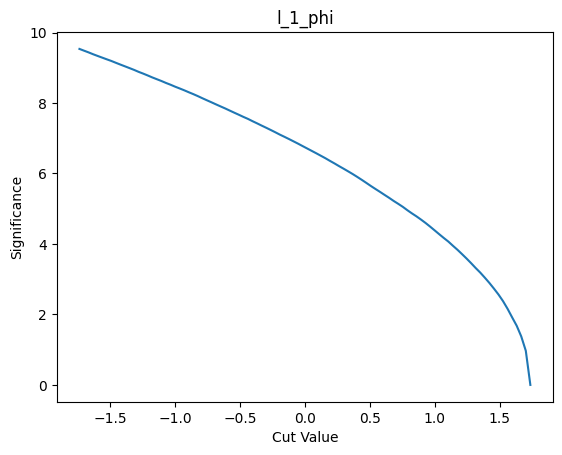

Best cut: -1.7347718477249143
Best significance: 30.151185075846684


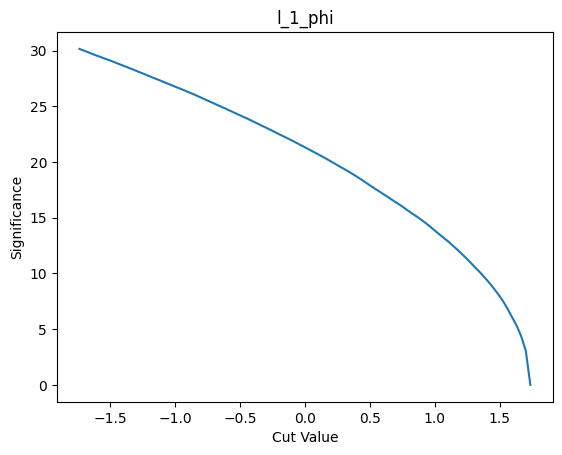

Best cut: 0.4285902678966522
Best significance: 0.9534657906215136


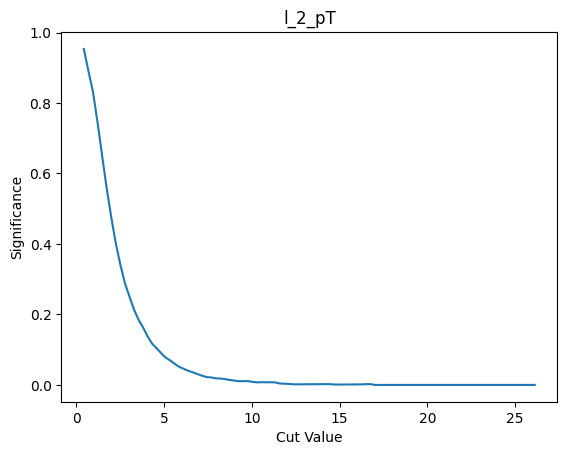

Best cut: 0.4285902678966522
Best significance: 3.015123569417194


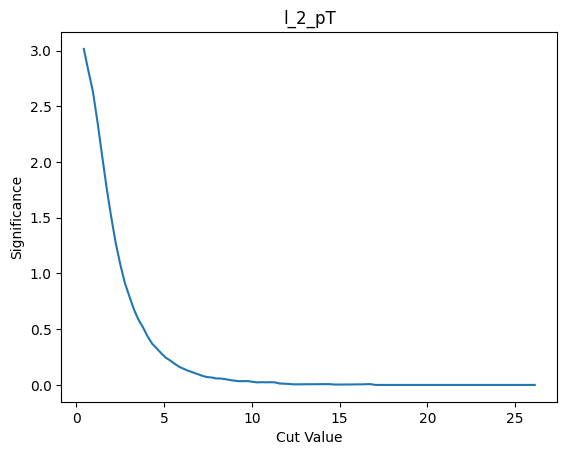

Best cut: 0.4285902678966522
Best significance: 9.534657906215136


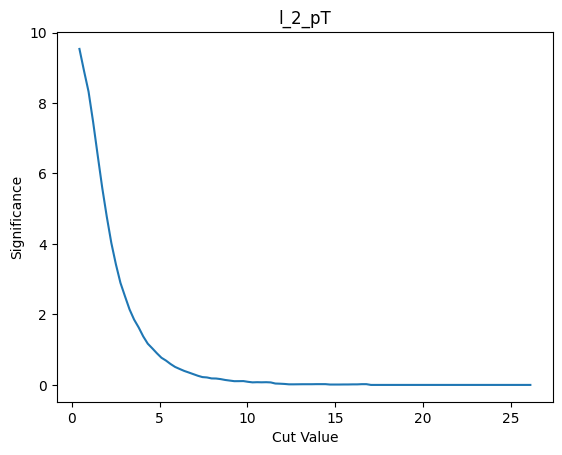

Best cut: 0.4285902678966522
Best significance: 30.151235694171937


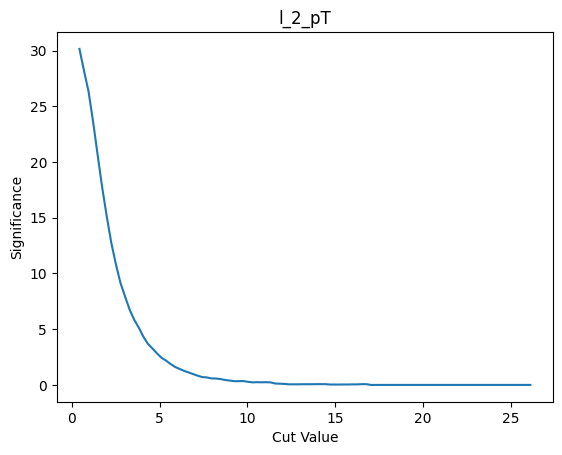

Best cut: -1.7342021465301511
Best significance: 0.9534586191543938


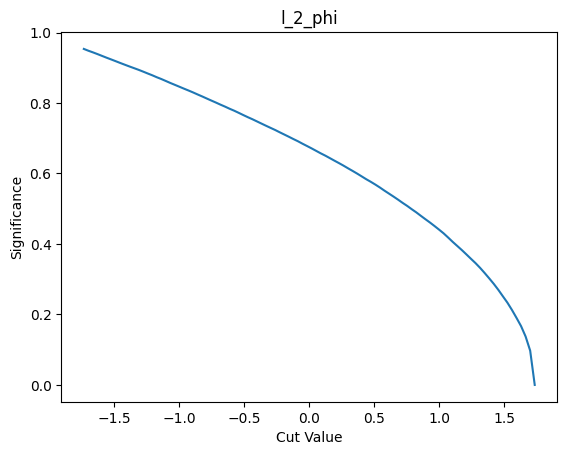

Best cut: -1.7342021465301511
Best significance: 3.01510089124693


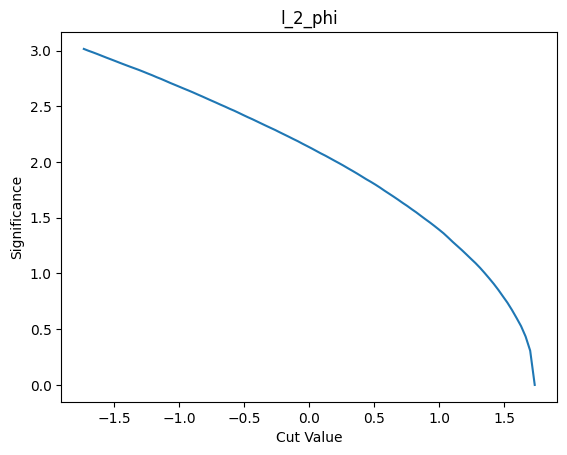

Best cut: -1.7342021465301511
Best significance: 9.534586191543937


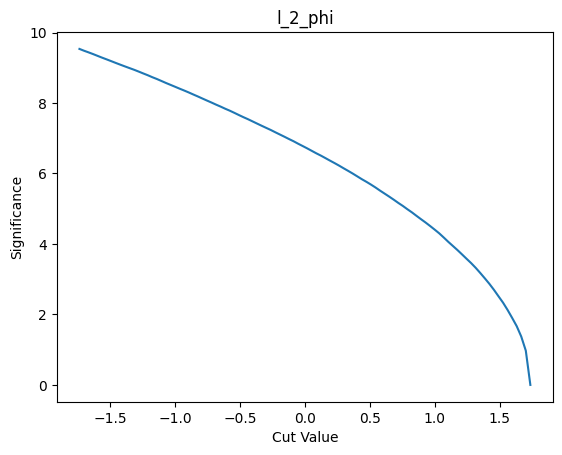

Best cut: -1.7342021465301511
Best significance: 30.1510089124693


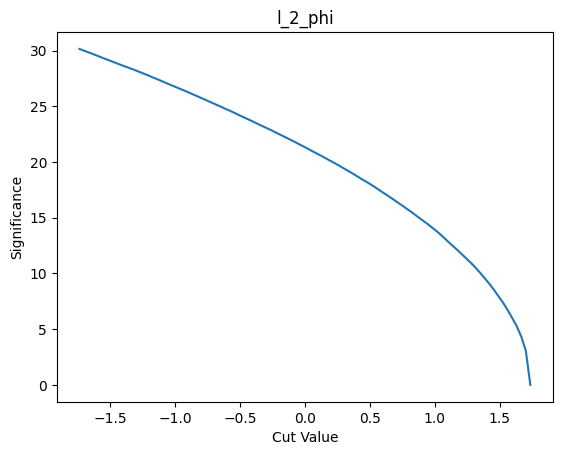

Best cut: 1.5511135718234899
Best significance: 1.4981331811618328


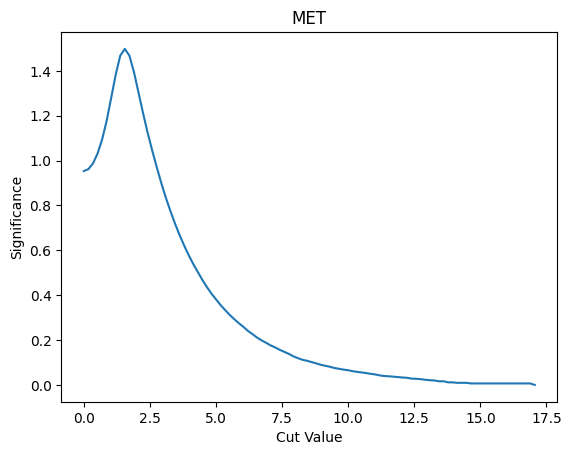

Best cut: 1.5511135718234899
Best significance: 4.7375130907450504


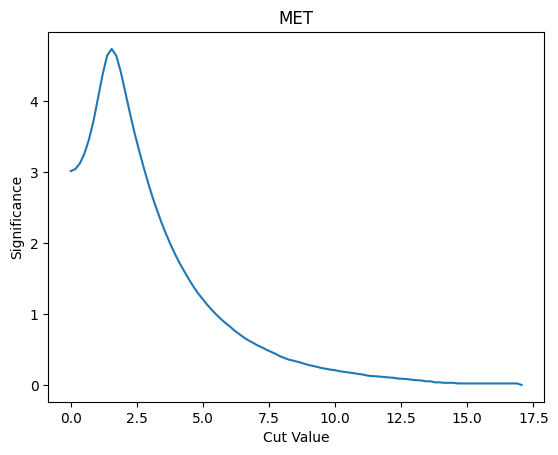

Best cut: 1.5511135718234899
Best significance: 14.981331811618327


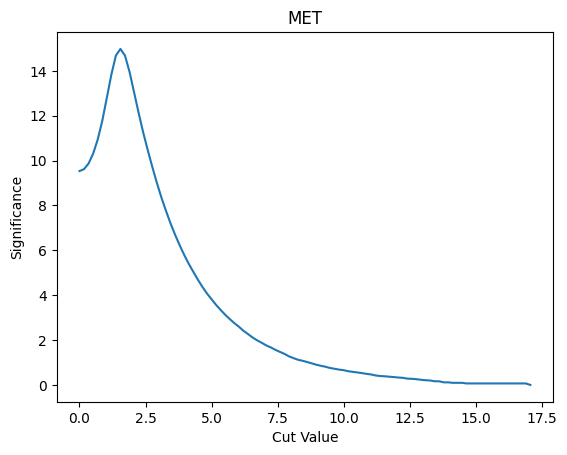

Best cut: 1.5511135718234899
Best significance: 47.37513090745051


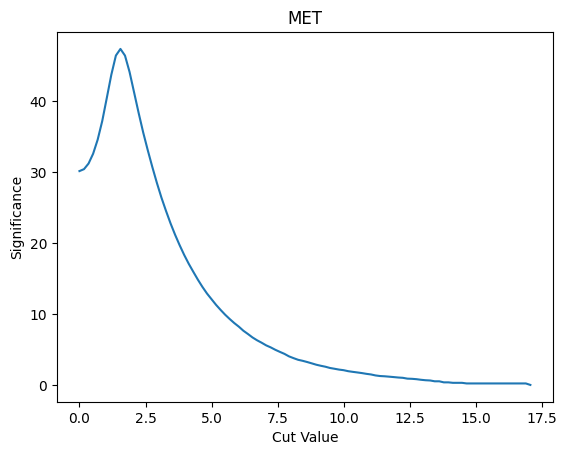

Best cut: -1.727111577987671
Best significance: 0.9534602198322932


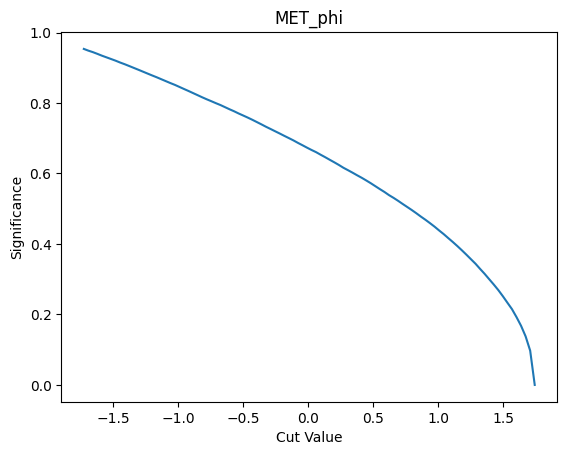

Best cut: -1.727111577987671
Best significance: 3.015105953034893


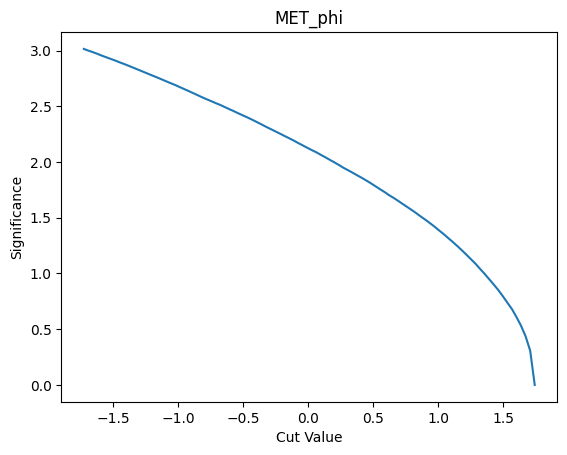

Best cut: -1.727111577987671
Best significance: 9.534602198322933


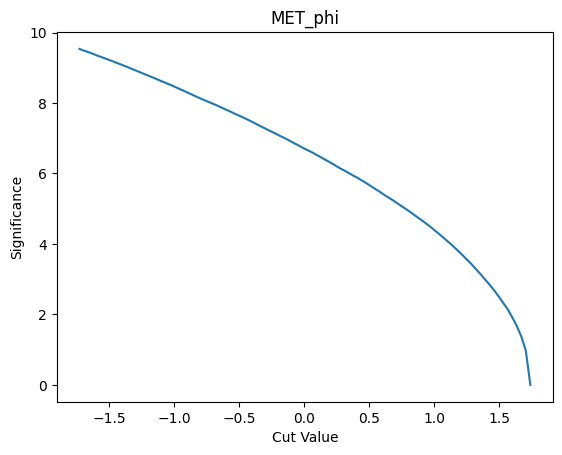

Best cut: -1.727111577987671
Best significance: 30.151059530348927


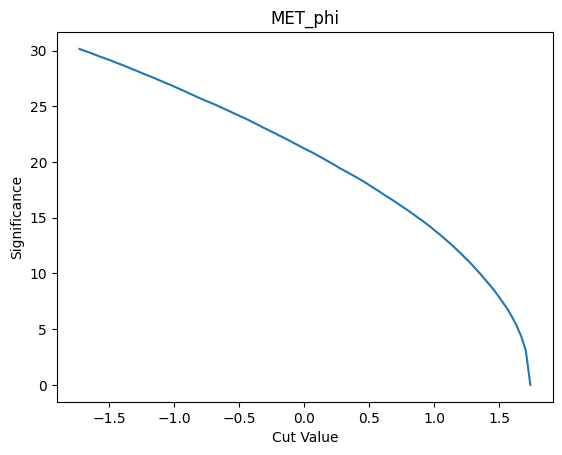

Best cut: 2.3324098325331755
Best significance: 0.9692320940577775


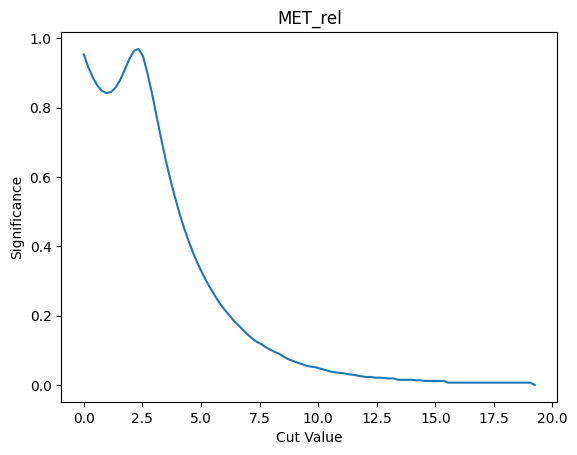

Best cut: 2.3324098325331755
Best significance: 3.064980998557127


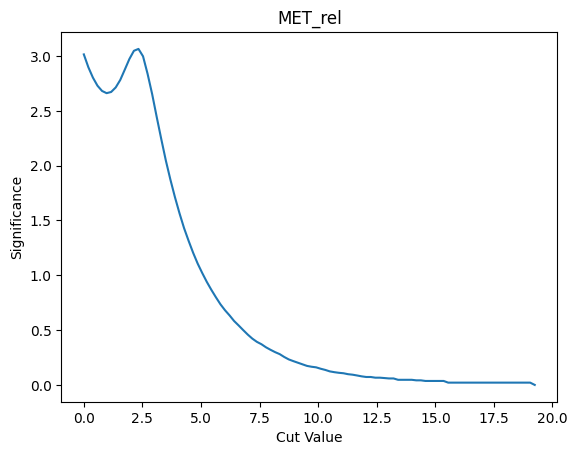

Best cut: 2.3324098325331755
Best significance: 9.692320940577774


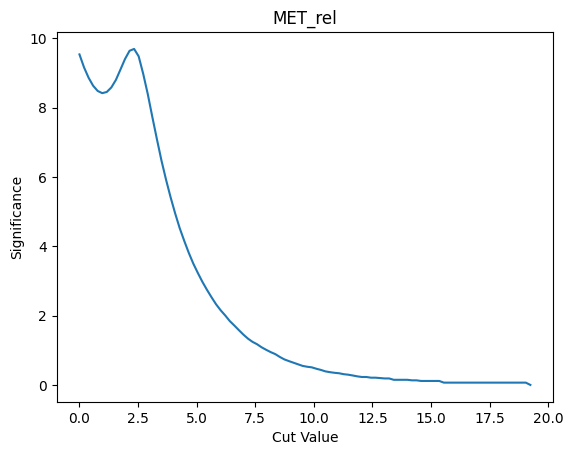

Best cut: 2.3324098325331755
Best significance: 30.649809985571274


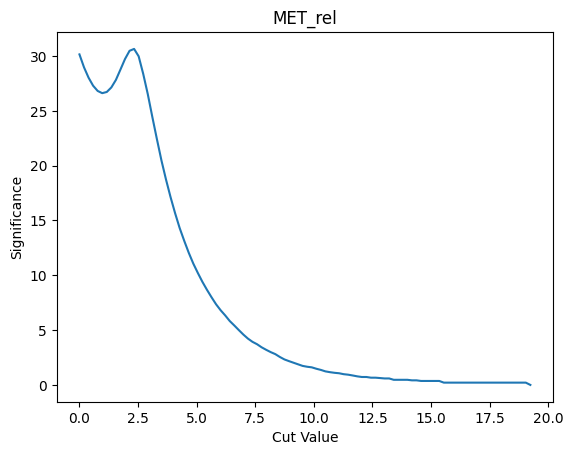

Best cut: 0.6036875536947539
Best significance: 1.042281434889043


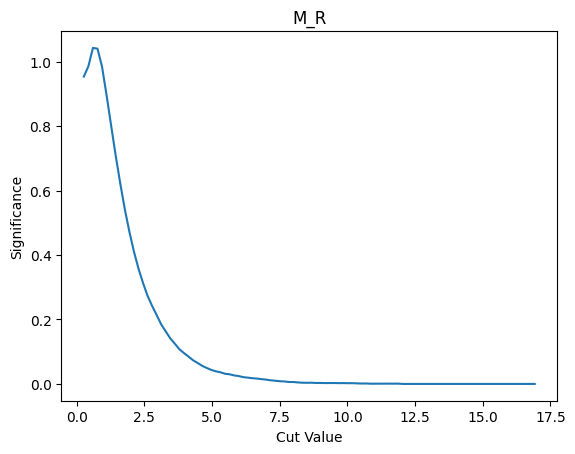

Best cut: 0.6036875536947539
Best significance: 3.2959832971578638


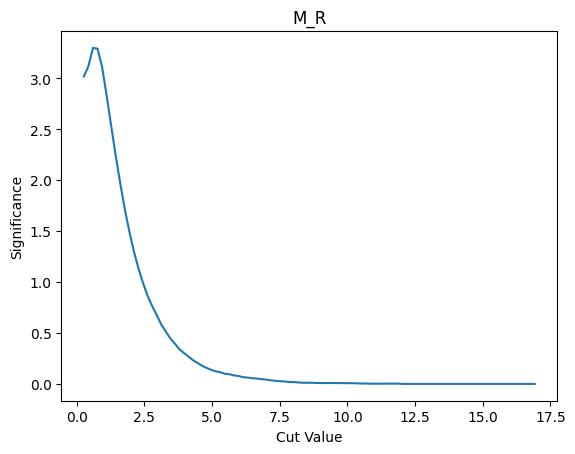

Best cut: 0.6036875536947539
Best significance: 10.42281434889043


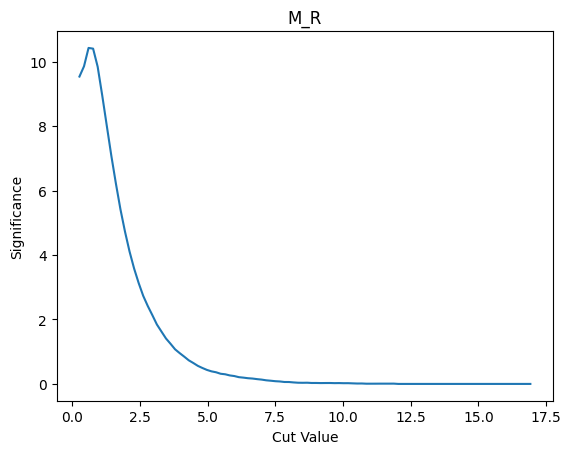

Best cut: 0.6036875536947539
Best significance: 32.959832971578635


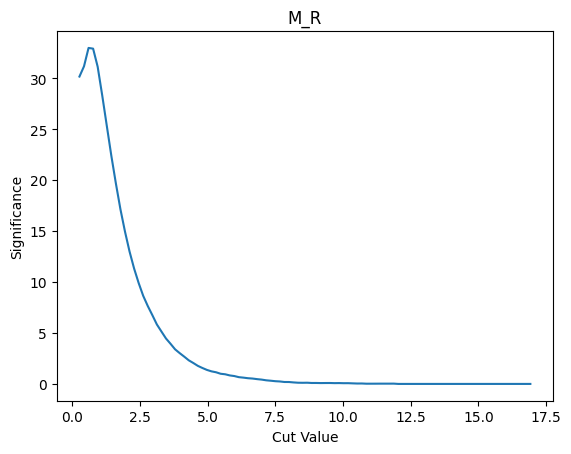

Best cut: 1.341938057462826
Best significance: 1.2677903474127132


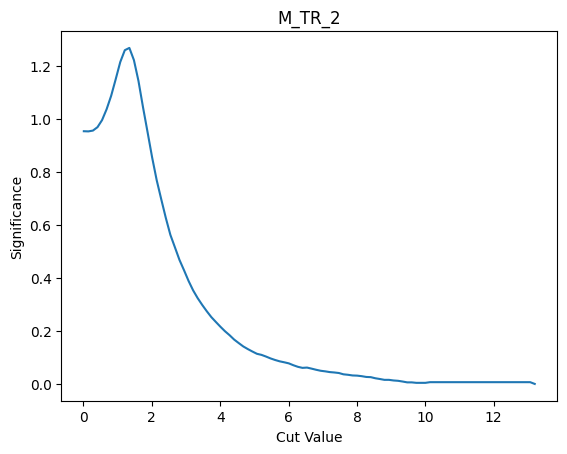

Best cut: 1.341938057462826
Best significance: 4.009105093400331


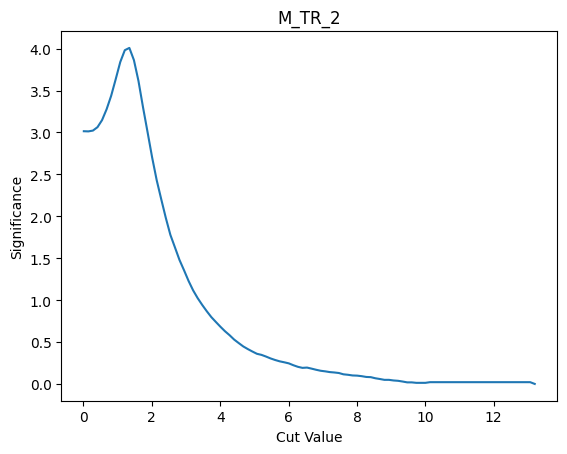

Best cut: 1.341938057462826
Best significance: 12.677903474127131


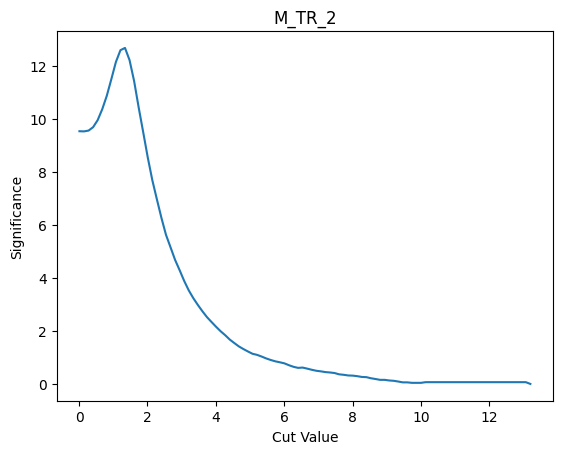

Best cut: 1.341938057462826
Best significance: 40.09105093400331


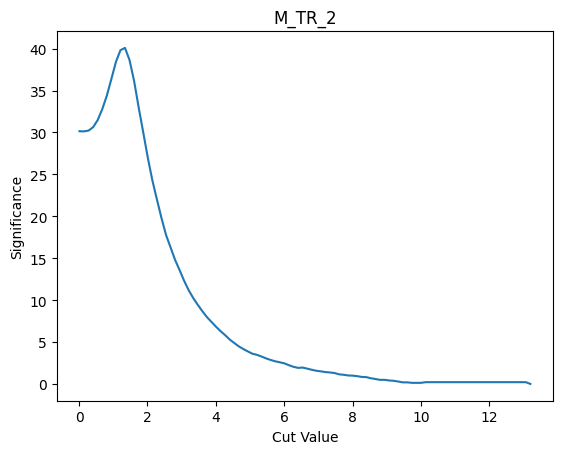

Best cut: 0.010751477442681788
Best significance: 0.9534641899295221


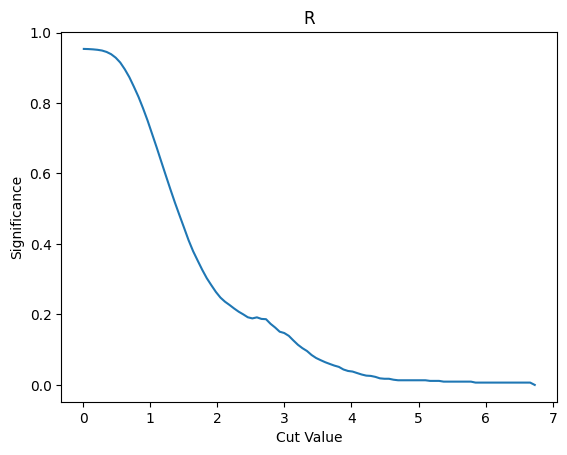

Best cut: 0.010751477442681788
Best significance: 3.015118507584668


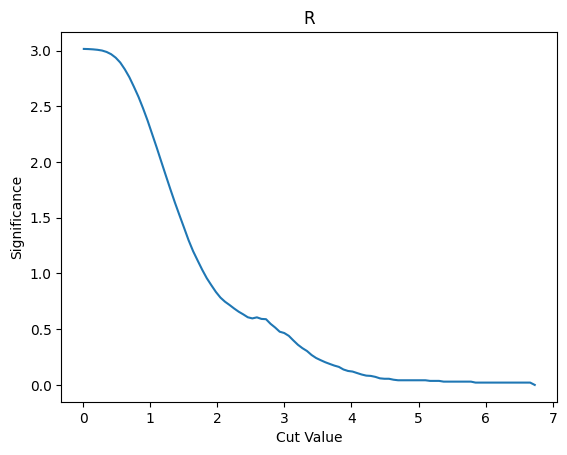

Best cut: 0.010751477442681788
Best significance: 9.534641899295222


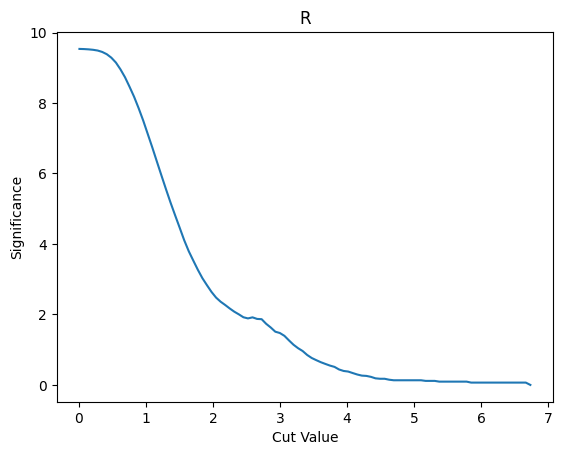

Best cut: 0.010751477442681788
Best significance: 30.151185075846684


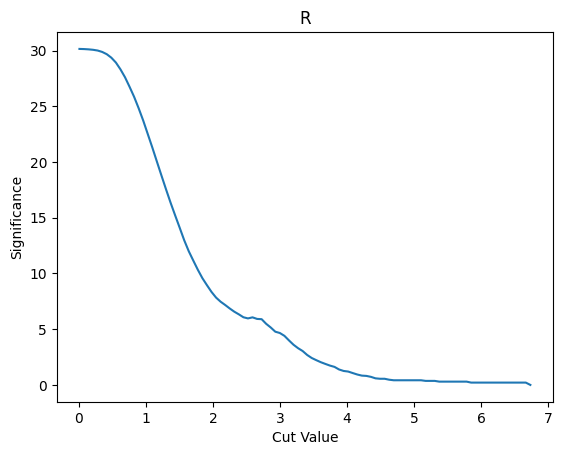

Best cut: 0.0
Best significance: 0.7755474220653249


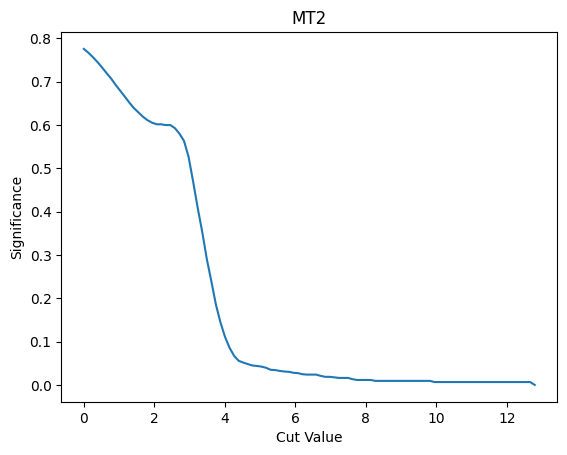

Best cut: 0.0
Best significance: 2.452496287198354


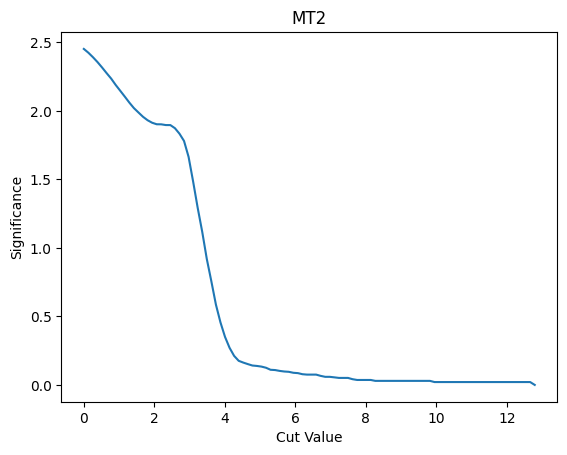

Best cut: 0.0
Best significance: 7.75547422065325


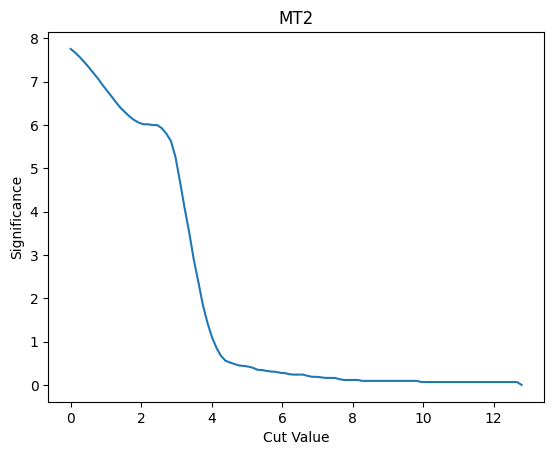

Best cut: 0.0
Best significance: 24.52496287198354


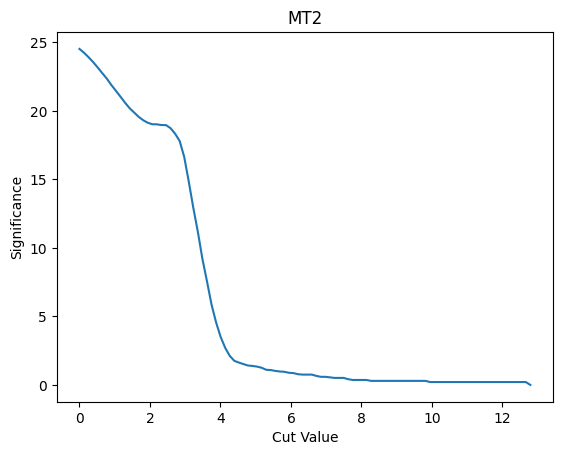

Best cut: 0.7126723072218775
Best significance: 1.046633839780809


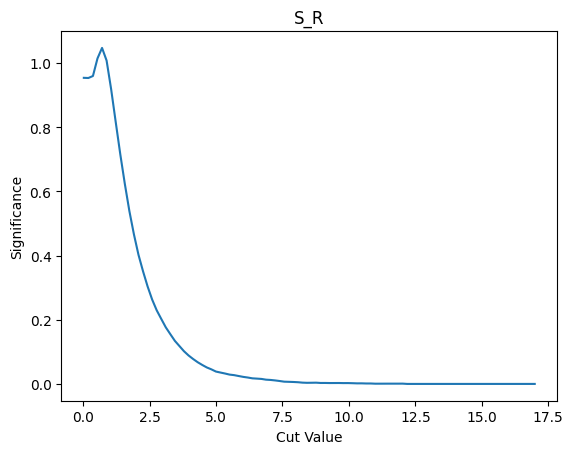

Best cut: 0.7126723072218775
Best significance: 3.309746809915103


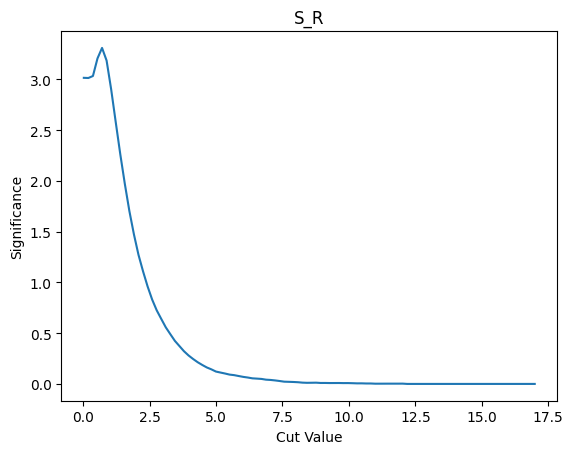

Best cut: 0.7126723072218775
Best significance: 10.46633839780809


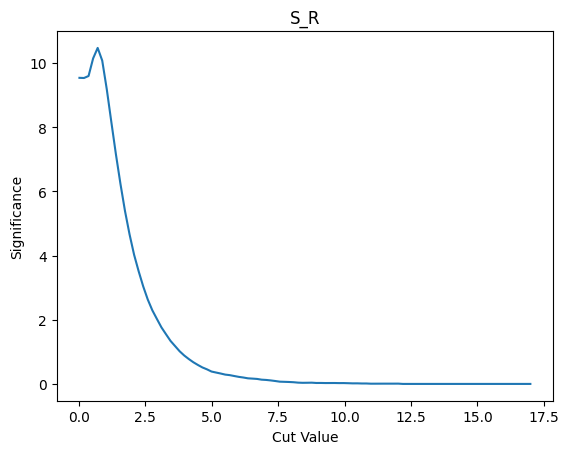

Best cut: 0.7126723072218775
Best significance: 33.09746809915104


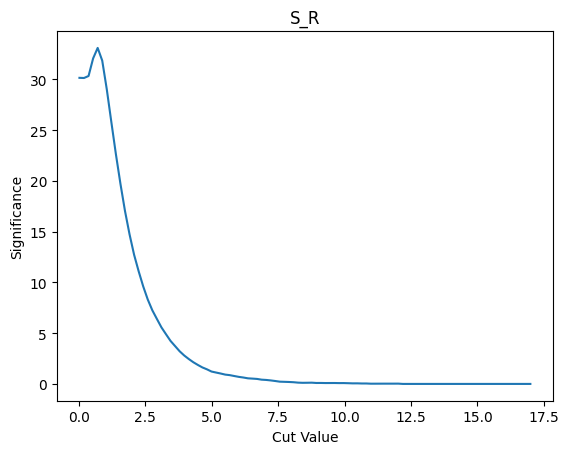

Best cut: 0.0044556171633303165
Best significance: 0.9534586191543938


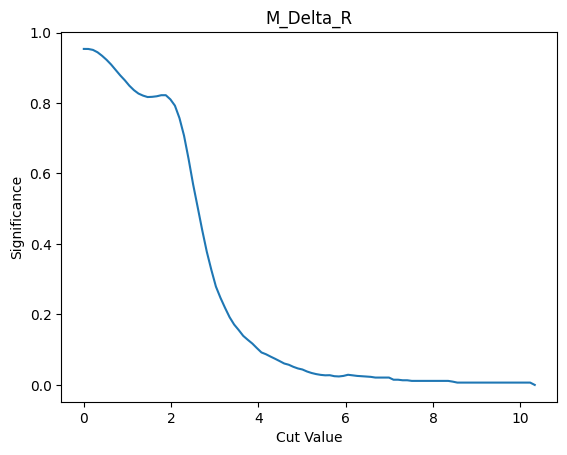

Best cut: 0.0044556171633303165
Best significance: 3.01510089124693


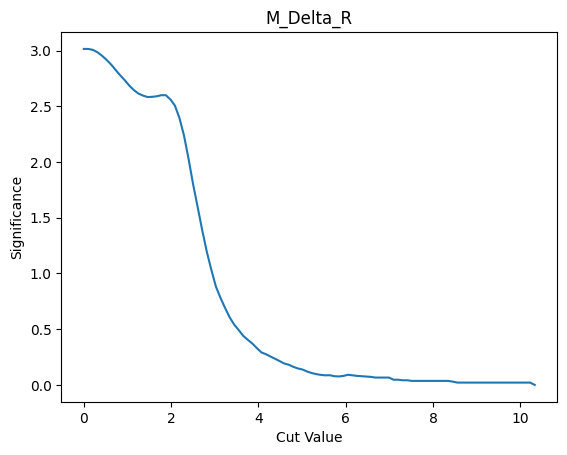

Best cut: 0.0044556171633303165
Best significance: 9.534586191543937


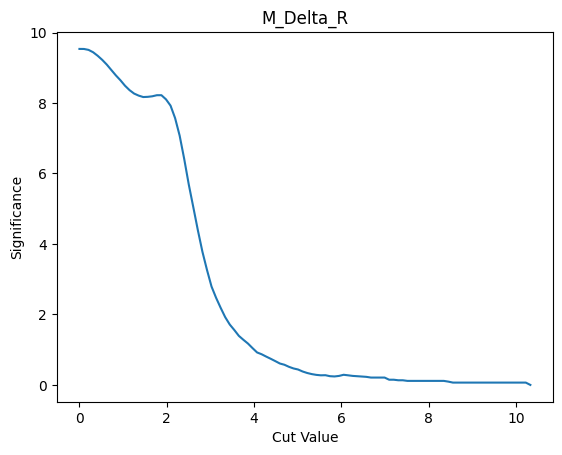

Best cut: 0.0044556171633303165
Best significance: 30.1510089124693


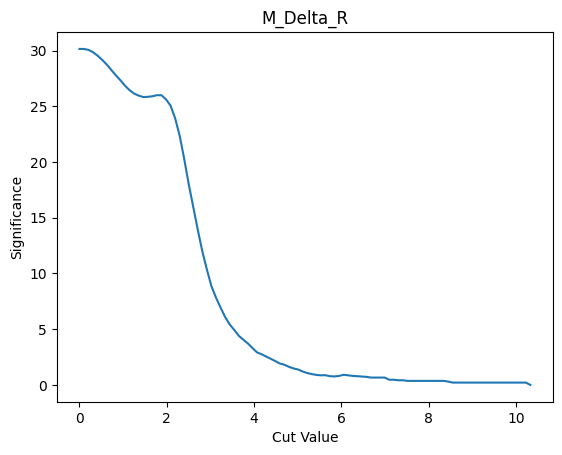

Best cut: 8.22400670585921e-06
Best significance: 0.9534586191543938


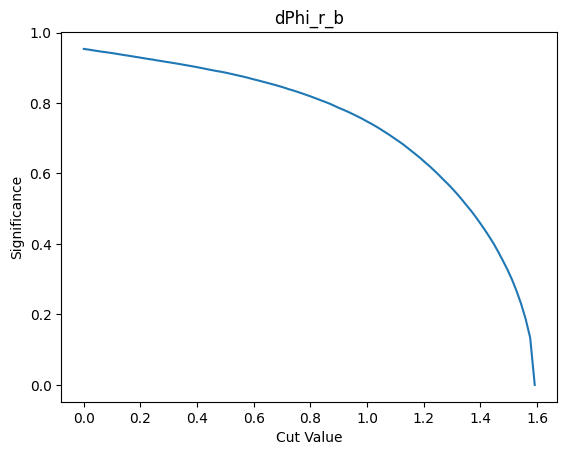

Best cut: 8.22400670585921e-06
Best significance: 3.01510089124693


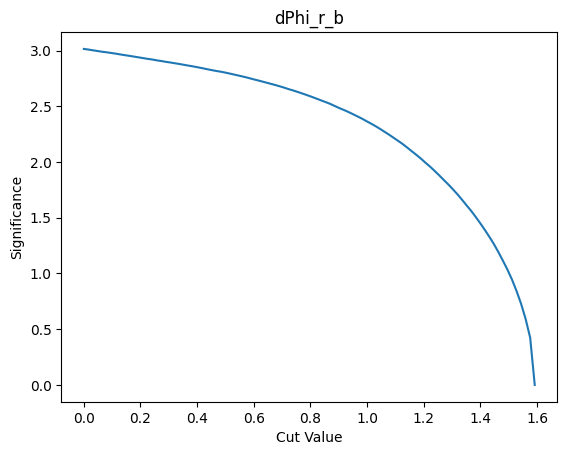

Best cut: 8.22400670585921e-06
Best significance: 9.534586191543937


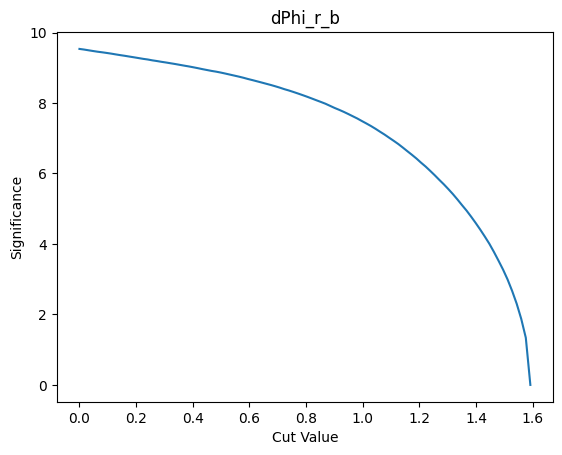

Best cut: 8.22400670585921e-06
Best significance: 30.1510089124693


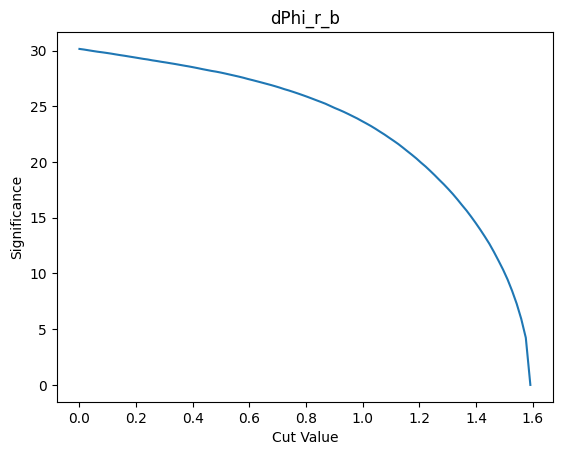

Best cut: 2.3886698841124604e-07
Best significance: 0.9534641899295221


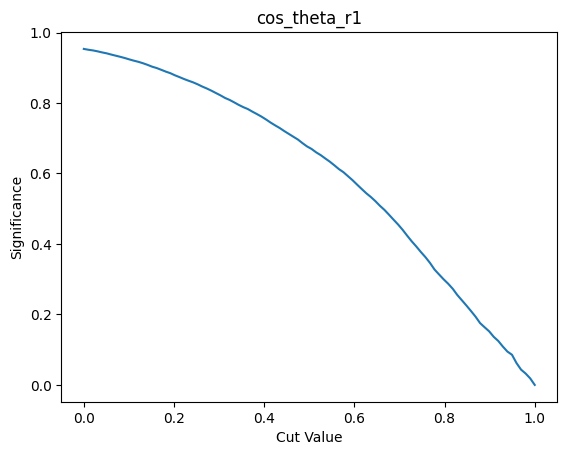

Best cut: 2.3886698841124604e-07
Best significance: 3.015118507584668


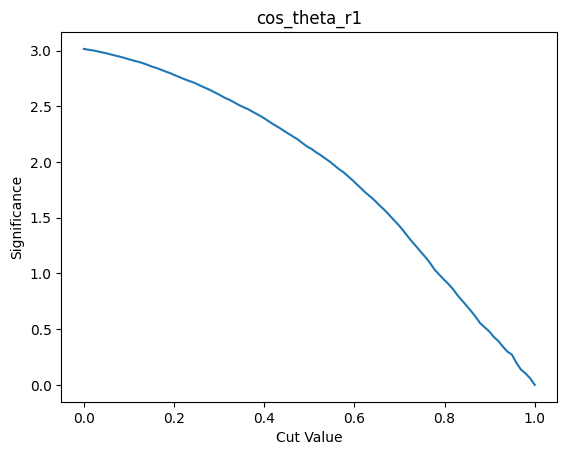

Best cut: 2.3886698841124604e-07
Best significance: 9.534641899295222


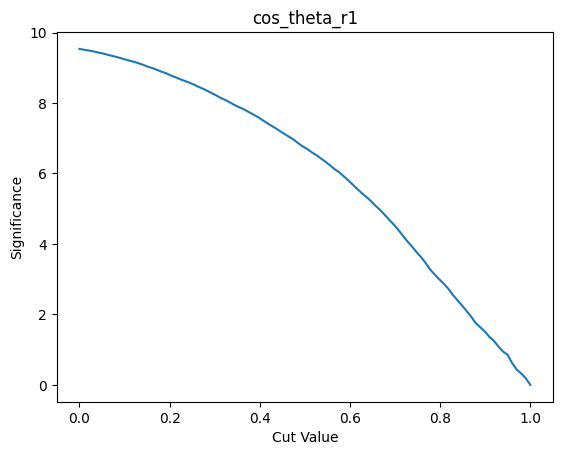

Best cut: 2.3886698841124604e-07
Best significance: 30.151185075846684


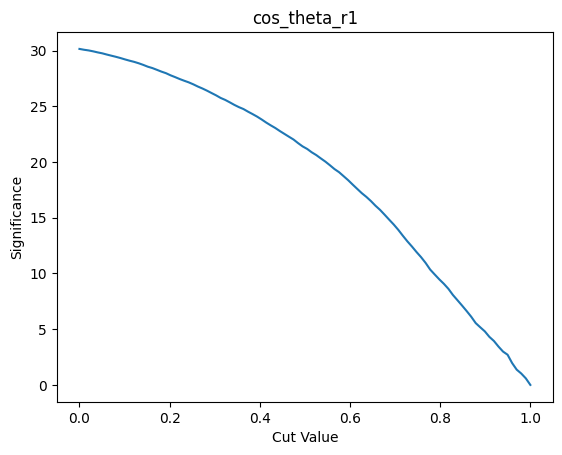

In [71]:
# I tested the function observable
# to make sure the TPR and FPR change as the cut value changes

for var in VarNames[1:]:

    if var in ["l_1_eta", "l_2_eta", "axial_MET"]:
        continue

    plot_significance(var, ">", 10, 100)
    plot_significance(var, ">", 100, 1000)
    plot_significance(var, ">", 1000, 10000)
    plot_significance(var, ">", 10000, 100000)

Best cut: 0.9171981320838736
Best significance: 3.719127486191184


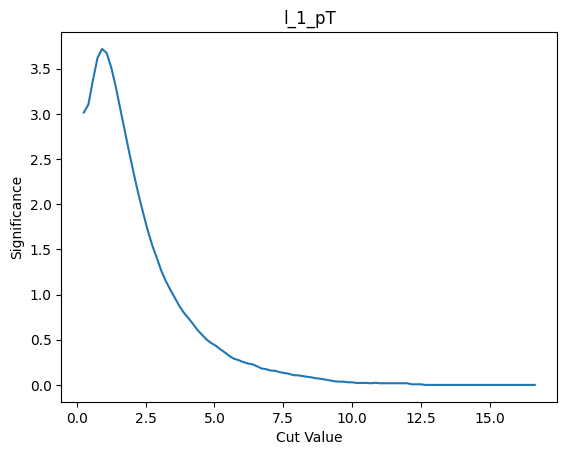

Best cut: 0.9171981320838736
Best significance: 11.760913764900563


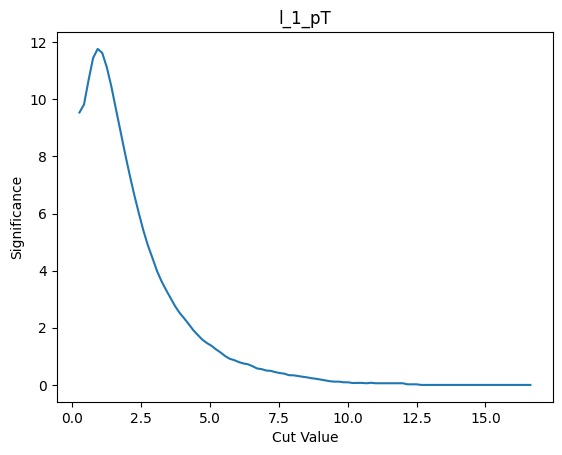

Best cut: 0.9171981320838736
Best significance: 37.19127486191184


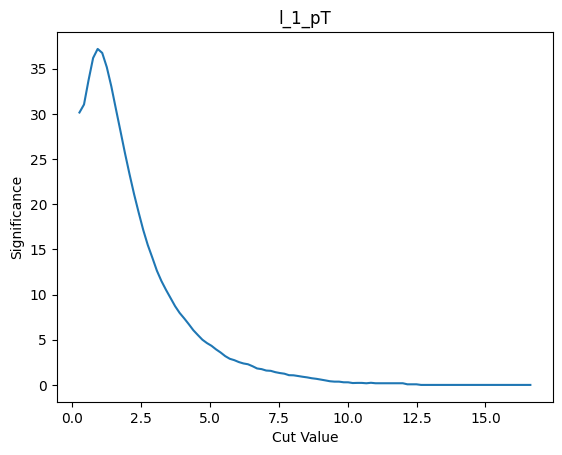

In [72]:
plot_significance(VarNames[1], ">", 100, 1000)

plot_significance(VarNames[1], ">", 1000, 10000)

plot_significance(VarNames[1], ">", 10000, 100000)

What I learned: I learned how the signal and background effciencies from Exercise 5.2 can be used to estimate how many signal and background events remain after making a cut.

I then use these values to calculate the significance for different cut values. The cut with the highest significance is the one that gives the best balance between keeping signal events and removing background events.

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [75]:
# Exericse 6.1
# For some guidence, I put this prompt
# and the data outputted in earlier 
# I asked it to walk me through this prompt and give me the assitance I need to 
# think through this problem 
# I will provided what I learned in the end 

In [76]:
# Exercise 6.1

scenarios = [
    [10, 100],
    [100, 1000],
    [1000, 10000],
    [10000, 100000]
]


variables = [
    "MET",
    "MET_rel",
    "M_R",
    "M_TR_2",
    "M_Delta_R",
    "cos_theta_r1"
]


def get_efficiency(data, cut, selection):

    if selection == ">":

        passed = np.sum(data > cut)

    elif selection == "<":

        passed = np.sum(data < cut)

    return passed / len(data)


def find_best_cut(var, selection, NS, NB):

    signal = np.array(df_sig[var])
    background = np.array(df_bkg[var])

    cuts = np.linspace(
        min(signal.min(), background.min()),
        max(signal.max(), background.max()),
        100
    )

    significance = []

    for cut in cuts:

        signal_eff = get_efficiency(
            signal,
            cut,
            selection
        )

        background_eff = get_efficiency(
            background,
            cut,
            selection
        )

        new_signal = signal_eff * NS
        new_background = background_eff * NB

        if new_signal + new_background > 0:

            sigma = new_signal / np.sqrt(
                new_signal + new_background
            )

        else:

            sigma = 0

        significance.append(sigma)

    best_index = np.argmax(significance)

    best_cut = cuts[best_index]
    best_significance = significance[best_index]

    return best_cut, best_significance

selection_choices = {
    "MET": ">",
    "MET_rel": ">",
    "M_R": ">",
    "M_TR_2": ">",
    "M_Delta_R": ">",
    "cos_theta_r1": ">"
}

for scenario in scenarios:

    NS = scenario[0]
    NB = scenario[1]

    print("Scenario")
    print("NS =", NS)
    print("NB =", NB)
    print()

    results = []

    for var in variables:

        best_cut, best_significance = find_best_cut(
            var,
            selection_choices[var],
            NS,
            NB
        )

        results.append([
            var,
            best_cut,
            best_significance
        ])

    results.sort(
        key = lambda x: x[2],
        reverse = True
    )

    print("Top 3 Observables")
    print()

    for result in results[:3]:

        print("Variable:", result[0])
        print("Best cut:", result[1])
        print("Significance:", result[2])
        print()

    print("-----------------------")

Scenario
NS = 10
NB = 100

Top 3 Observables

Variable: MET
Best cut: 1.5511135718234899
Significance: 1.4981331811618328

Variable: M_TR_2
Best cut: 1.341938057462826
Significance: 1.2677903474127132

Variable: M_R
Best cut: 0.6036875536947539
Significance: 1.042281434889043

-----------------------
Scenario
NS = 100
NB = 1000

Top 3 Observables

Variable: MET
Best cut: 1.5511135718234899
Significance: 4.7375130907450504

Variable: M_TR_2
Best cut: 1.341938057462826
Significance: 4.009105093400331

Variable: M_R
Best cut: 0.6036875536947539
Significance: 3.2959832971578638

-----------------------
Scenario
NS = 1000
NB = 10000

Top 3 Observables

Variable: MET
Best cut: 1.5511135718234899
Significance: 14.981331811618327

Variable: M_TR_2
Best cut: 1.341938057462826
Significance: 12.677903474127131

Variable: M_R
Best cut: 0.6036875536947539
Significance: 10.42281434889043

-----------------------
Scenario
NS = 10000
NB = 100000

Top 3 Observables

Variable: MET
Best cut: 1.5511135718

here is a rough idea of whwat i going on. The function goes ahead and tries a cut and finds a singla effceincy, and then an baground efficiney. Then it finds the remoaning singal/rackground, adn then calualte the overall significace. Then it ocmapres the reuslts with eachotehr to find the best result.

In this section, i learned how to use significanesfrom observations to find a cut that producdes the highest signfiicace. Then i used it to compare the resilts and then find the best significace. Baed on the output, it seems like the best signiface was the M_TR_2 and the M_R. I also found a proportion where as the number of events increased, the signigicae also increased as well.

In [78]:
# exercise 6.2 - we wil use those values to craete eth code. 
# Assited with the help of GPT: the things we need to calculate are the signial efficieny
# background efficieny, N'_S and N'_B and the significace. 
# Here is the GPT assited code that I got
# Exercise 6.2

cuts = [
    ["MET", 1.5511135718234899],
    ["M_TR_2", 1.341938057462826],
    ["M_R", 0.6036875536947539]
]

def cut_flow(NS, NB):

    signal_data = df_sig.copy()
    background_data = df_bkg.copy()

    results = []

    for cut in cuts:

        var = cut[0]
        cut_value = cut[1]

        signal_data = signal_data[
            signal_data[var] > cut_value
        ]

        background_data = background_data[
            background_data[var] > cut_value
        ]

        signal_eff = len(signal_data) / len(df_sig)
        background_eff = len(background_data) / len(df_bkg)

        new_signal = signal_eff * NS
        new_background = background_eff * NB

        if new_signal + new_background > 0:

            significance = new_signal / np.sqrt(
                new_signal + new_background
            )

        else:

            significance = 0

        results.append([
            var,
            cut_value,
            signal_eff,
            background_eff,
            new_signal,
            new_background,
            significance
        ])

    return results

In [79]:
# Then we used tabulate to diplay it so I could anayluse it
def display_cut_flow(NS, NB):

    results = cut_flow(NS, NB)

    headers = [
        "Cut",
        "xc",
        "Signal Efficiency",
        "Background Efficiency",
        "N'S",
        "N'B",
        "Significance"
    ]

    print("NS =", NS, "NB =", NB)

    display(HTML(tabulate.tabulate(
        results,
        headers = headers,
        tablefmt = "html",
        floatfmt = ".3f"
    )))

In [80]:
display_cut_flow(10, 100)

display_cut_flow(100, 1000)

display_cut_flow(1000, 10000)

display_cut_flow(10000, 100000)

NS = 10 NB = 100


Cut,xc,Signal Efficiency,Background Efficiency,N'S,N'B,Significance
MET,1.551,0.322,0.014,3.215,1.391,1.498
M_TR_2,1.342,0.227,0.010,2.273,0.997,1.257
M_R,0.604,0.219,0.009,2.187,0.922,1.240


NS = 100 NB = 1000


Cut,xc,Signal Efficiency,Background Efficiency,N'S,N'B,Significance
MET,1.551,0.322,0.014,32.151,13.906,4.738
M_TR_2,1.342,0.227,0.010,22.725,9.972,3.974
M_R,0.604,0.219,0.009,21.867,9.219,3.922


NS = 1000 NB = 10000


Cut,xc,Signal Efficiency,Background Efficiency,N'S,N'B,Significance
MET,1.551,0.322,0.014,321.512,139.056,14.981
M_TR_2,1.342,0.227,0.010,227.250,99.721,12.568
M_R,0.604,0.219,0.009,218.674,92.187,12.403


NS = 10000 NB = 100000


Cut,xc,Signal Efficiency,Background Efficiency,N'S,N'B,Significance
MET,1.551,0.322,0.014,3215.119,1390.556,47.375
M_TR_2,1.342,0.227,0.010,2272.503,997.212,39.742
M_R,0.604,0.219,0.009,2186.743,921.867,39.221


What I learned: I learned how a cut flow applies multiple selections one after another instead of treating each oberserable independently.

This allowed me to see whether each addional cut impvoed the separation between signal and background or whether it removed too much signal.

Based on there results, here is what I was able to asertain. To be hoesnt, Ihad to use GPT to help me undersatnd what was goin gon. I fed it the tables and asked to help me undersatnd what was goin gon as if I was completely new to this data. In summary, the MET cut was the most useful as it kept about 32% of the singla while taking down the background to 1.4% about. When the M_TR_2 and the M_R cuts were added, the background decreased even more but so did the signal. I also noticedd that the efficient sated the same for all four seneries, which can mean that since i applied the same cut to the same data, it would result in same efficieny. The increase in singal and background events reuslted in an overall significace to increase. 

In [82]:
# Exericse 6.3 
# we need to stat by finding the correlations between the differnc values 
# Exercise 6.3

all_variables = VarNames[1:]

for var1 in ["MET", "M_TR_2", "M_R"]:

    for var2 in ["MET", "M_TR_2", "M_R"]:

        i = all_variables.index(var1)
        j = all_variables.index(var2)

        print(
            var1,
            "and",
            var2,
            "=",
            round(corrcoef_all[i][j], 3)
        )

MET and MET = 1.0
MET and M_TR_2 = 0.72
MET and M_R = 0.264
M_TR_2 and MET = 0.72
M_TR_2 and M_TR_2 = 1.0
M_TR_2 and M_R = 0.577
M_R and MET = 0.264
M_R and M_TR_2 = 0.577
M_R and M_R = 1.0


This is imporatnt information because it shows how strong/weak correlation there is between the values . As you can see that the MET alone as a strong positve correlation, while say the MET and M_R have a slihghly lower positve correlation. 

In [84]:
met_cut = 1.5511135718234899
signal_after_met = df_sig[
    df_sig["MET"] > met_cut
]

background_after_met = df_bkg[
    df_bkg["MET"] > met_cut
]

In [85]:
def optimize_second_cut(
    signal_data,
    background_data,
    var,
    NS,
    NB
):

    signal = np.array(signal_data[var])
    background = np.array(background_data[var])

    cuts = np.linspace(
        min(signal.min(), background.min()),
        max(signal.max(), background.max()),
        100
    )

    significance = []

    for cut in cuts:

        signal_passed = np.sum(signal > cut)
        background_passed = np.sum(background > cut)

        signal_eff = signal_passed / len(df_sig)
        background_eff = background_passed / len(df_bkg)

        new_signal = signal_eff * NS
        new_background = background_eff * NB

        if new_signal + new_background > 0:

            sigma = new_signal / np.sqrt(
                new_signal + new_background
            )

        else:

            sigma = 0

        significance.append(sigma)

    best_index = np.argmax(significance)

    return cuts[best_index], significance[best_index]

In [86]:
best_cut, best_sigma = optimize_second_cut(
    signal_after_met,
    background_after_met,
    "M_TR_2",
    10,
    100
)

print("MET was applied first")
print("New best M_TR_2 cut:", best_cut)
print("New significance:", best_sigma)

MET was applied first
New best M_TR_2 cut: 0.017576532438397408
New significance: 1.4981199496324236


In [87]:
# The code here is derived by ChatGPT becayse I was completely lost. I focued on 
# tyring to undesrstand the output and what the quesiton was asking me to do 
mtr_cut = 1.341938057462826

signal_after_mtr = df_sig[
    df_sig["M_TR_2"] > mtr_cut
]

background_after_mtr = df_bkg[
    df_bkg["M_TR_2"] > mtr_cut
]

In [88]:
best_cut, best_sigma = optimize_second_cut(
    signal_after_mtr,
    background_after_mtr,
    "MET",
    10,
    100
)

print("M_TR_2 was applied first")
print("New best MET cut:", best_cut)
print("New significance:", best_sigma)

M_TR_2 was applied first
New best MET cut: 1.0805190714320752
New significance: 1.2742524664614776


6.3 PART: 

Here is what I learned: I learned how to optimize each observation separately does not give the best reuslt when teh cuts are combined. It is better to find the correlation. After the first selection was applied, I nocied that the singl and background was changed. This is best result it got for this portion. I re-optimzed the second oersation after applying the first cut. I also learned how to reverse order the selections so we can see if the observation applied before could affect the final signifiace. This showed me why the order of selections and correlations between oversvales do infact matter. 
On the more techicl side, I learned how to use functions to generalize results. I learned how to use set up differnt functions to take in differnt data and use it to create new obserbations. I never had to think about stuff like this, and I learned how to go about complex problems like this. That is a learning that applied for the entirety of this lab. 

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



/var/folders/tx/t8s4wmnj1nl4nnk3n0xb0v800000gn/T/ipykernel_7675/946906791.py:45: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  auc = np.trapz(tpr, fpr)


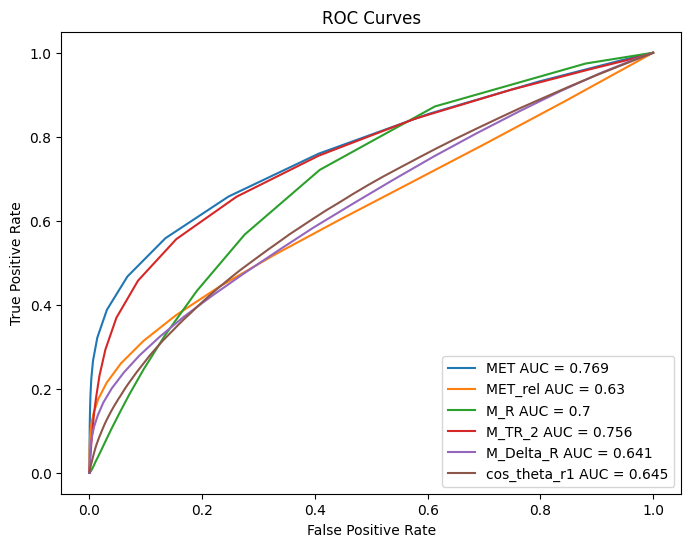

In [91]:
# EXERCISE 7.1

# using the skills that I learned nbefore, I tried to do it myself. 
varibles = [ "MET", "M_TR_2", "M_R"]

plt.figure(figsize = (8, 6))

# At this point I used GPT to help me get the ROC curve, but I used previous code on ROC and or 
# similar code. I asked chapt GPT to guide me in solve this probkem. However, I focused on a more 
# analytic approach. 

for var in variables:

    signal = np.array(df_sig[var])
    background = np.array(df_bkg[var])

    cuts = np.linspace(
        min(signal.min(), background.min()),
        max(signal.max(), background.max()),
        100
    )

    tpr = []
    fpr = []

    for cut in cuts:

        signal_passed = np.sum(signal > cut)
        background_passed = np.sum(background > cut)

        signal_eff = signal_passed / len(signal)
        background_eff = background_passed / len(background)

        tpr.append(signal_eff)
        fpr.append(background_eff)

    tpr = np.array(tpr)
    fpr = np.array(fpr)

    order = np.argsort(fpr)

    fpr = fpr[order]
    tpr = tpr[order]

    auc = np.trapz(tpr, fpr)

    plt.plot(
        fpr,
        tpr,
        label = var + " AUC = " + str(round(auc, 3))
    )

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")

plt.legend()
plt.show()

MET = 0.769
M_TR_2 = 0.756
M_R = 0.700
cos_theta_r1 = 0.645
M_Delta_R = 0.641
MET_rel = 0.630

The closer you are to the 1, it means that there is better seperation beytween the values. At the mid point, you can assume that the varibles are barely better than random at separating into two groups. GPT helped me undrstand what the curves meant, and according to it, a better ROC curve stays closer to the upper-left side of the graph because that represents keeping more signal while accepting less background. Out of all these values, it seems like the MET and M_TR_2 are the strongest indivudial oversvables ot of the ones compred. 

On the more tehnical side, I learned btter how to use ROC curves and used np.linspace(). I also am getting a better hang of how to use GPT to learn more about differnt, unfamilar concepts, rather than just copy-pasting and calling it a day. 

In [93]:
# EXERICSE 7.2

def plot_roc(variables):

    plt.figure(figsize = (8, 6))

    for var in variables:

        signal = np.array(df_sig[var])
        background = np.array(df_bkg[var])

        cuts = np.linspace(
            min(signal.min(), background.min()),
            max(signal.max(), background.max()),
            100
        )

        tpr = []
        fpr = []

        for cut in cuts:

            signal_passed = np.sum(signal > cut)
            background_passed = np.sum(background > cut)

            signal_eff = signal_passed / len(signal)
            background_eff = background_passed / len(background)

            tpr.append(signal_eff)
            fpr.append(background_eff)

        tpr = np.array(tpr)
        fpr = np.array(fpr)

        order = np.argsort(fpr)

        fpr = fpr[order]
        tpr = tpr[order]

        auc = np.trapezoid(tpr, fpr)

        plt.plot(
            fpr,
            tpr,
            label = var + " AUC = " + str(round(auc, 3))
        )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves")

    plt.legend()
    plt.show()

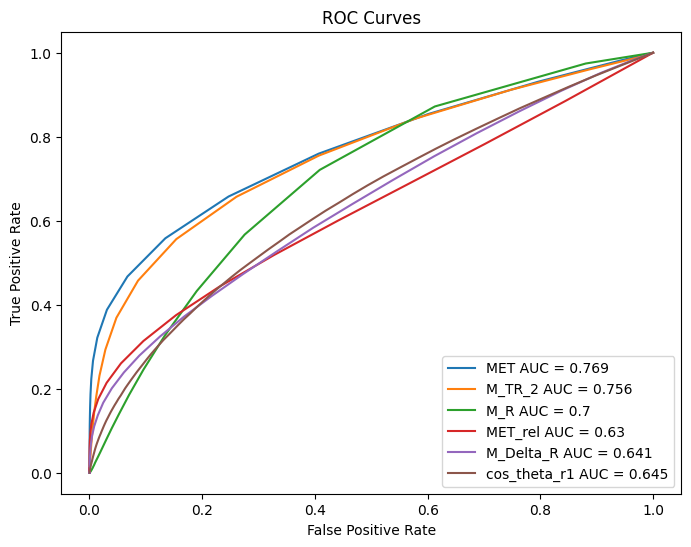

In [94]:
variables = [
    "MET",
    "M_TR_2",
    "M_R", "MET_rel",
    "M_Delta_R",
    "cos_theta_r1"
]

plot_roc(variables)

In this portion, similar to that of old exericse, I simplied a complex code block int oa simple one that allows me to understand the code better. Instead of reapleating all the ROC code everytime, we can now call plot_roc(). 

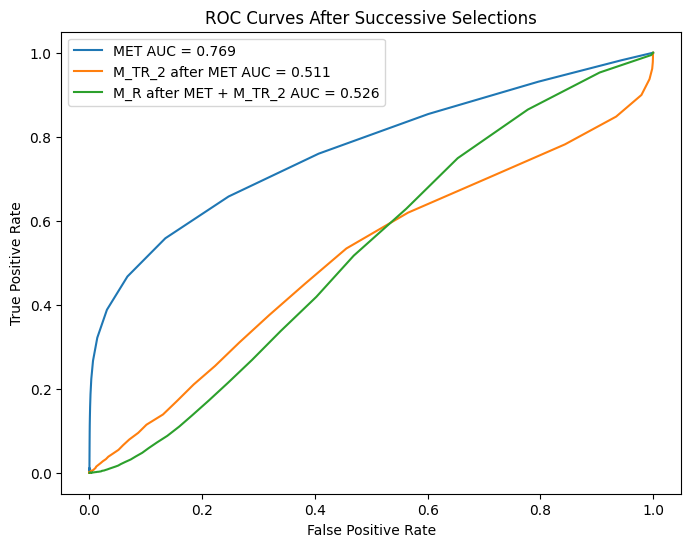

In [96]:
# EXERCISE 7.3 
# for this secction, I wanted to undersatnd how to go about the problem and undersatnd what the
# code was doing. Here is what I learned with the help of GPT:
# the code is essentially taking the orignal singla data
# making the ROC cirve for MEt adn then applying the cut from exericse 6 as the prompt asks
# then it goes alread and makes the ROC cruve for M_TR_2, and then does the same and applies the cut
# Then all the 3 ROC cirves are overalied so we can see the difference and see the successive selections 

def get_roc(signal_data, background_data, var):

    signal = np.array(signal_data[var])
    background = np.array(background_data[var])

    cuts = np.linspace(
        min(signal.min(), background.min()),
        max(signal.max(), background.max()),
        100
    )

    tpr = []
    fpr = []

    for cut in cuts:

        signal_passed = np.sum(signal > cut)
        background_passed = np.sum(background > cut)

        signal_eff = signal_passed / len(signal)
        background_eff = background_passed / len(background)

        tpr.append(signal_eff)
        fpr.append(background_eff)

    tpr = np.array(tpr)
    fpr = np.array(fpr)

    order = np.argsort(fpr)

    fpr = fpr[order]
    tpr = tpr[order]

    auc = np.trapezoid(tpr, fpr)

    return fpr, tpr, auc


signal_data = df_sig.copy()
background_data = df_bkg.copy()



met_fpr, met_tpr, met_auc = get_roc(
    signal_data,
    background_data,
    "MET"
)



signal_data = signal_data[
    signal_data["MET"] > 1.5511135718234899
]

background_data = background_data[
    background_data["MET"] > 1.5511135718234899
]


mtr_fpr, mtr_tpr, mtr_auc = get_roc(
    signal_data,
    background_data,
    "M_TR_2"
)


signal_data = signal_data[
    signal_data["M_TR_2"] > 1.341938057462826
]

background_data = background_data[
    background_data["M_TR_2"] > 1.341938057462826
]


mr_fpr, mr_tpr, mr_auc = get_roc(
    signal_data,
    background_data,
    "M_R"
)


plt.figure(figsize = (8, 6))

plt.plot(
    met_fpr,
    met_tpr,
    label = "MET AUC = " + str(round(met_auc, 3))
)

plt.plot(
    mtr_fpr,
    mtr_tpr,
    label = "M_TR_2 after MET AUC = " + str(round(mtr_auc, 3))
)

plt.plot(
    mr_fpr,
    mr_tpr,
    label = "M_R after MET + M_TR_2 AUC = " + str(round(mr_auc, 3))
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves After Successive Selections")

plt.legend()
plt.show()

What I learned: I learned that an observable can be useful when it is tested by itself. MET had an AUC of about 0.769, which showed that it had good ability to separate signal from background. The AUC for M_TR_2 dropped to about 0.511. 0.5, as seen before, means that there is little to no separation between signal and background.In additon to this, this also helps explain why the significance decreased in Exercise 6 when I added those extra selections.

On a more technical side, I learned how to reuse the same ROC function with filtered datasets. Instead of always using the original signal and background data, I passed in the data that remained after each cut.

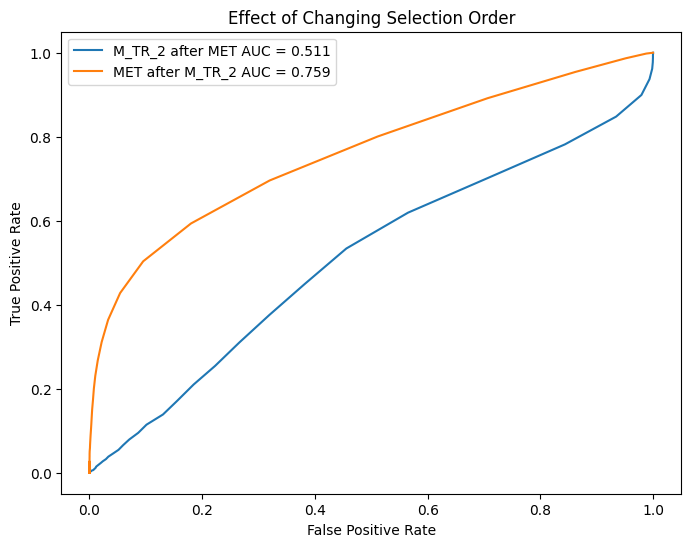

In [98]:
# Exercise 7.4
# for this part, MET gets first choice at separating the data. We want to see how the ROC function changes 
# as the order of the successive slections changed. 
# Here is the code: 

signal_data = df_sig.copy()
background_data = df_bkg.copy()

signal_data = signal_data[
    signal_data["MET"] > 1.5511135718234899
]

background_data = background_data[
    background_data["MET"] > 1.5511135718234899
]

mtr_fpr_1, mtr_tpr_1, mtr_auc_1 = get_roc(
    signal_data,
    background_data,
    "M_TR_2"
)

signal_data = df_sig.copy()
background_data = df_bkg.copy()

signal_data = signal_data[
    signal_data["M_TR_2"] > 1.341938057462826
]

background_data = background_data[
    background_data["M_TR_2"] > 1.341938057462826
]

met_fpr_2, met_tpr_2, met_auc_2 = get_roc(
    signal_data,
    background_data,
    "MET"
)

plt.figure(figsize = (8, 6))

plt.plot(
    mtr_fpr_1,
    mtr_tpr_1,
    label = "M_TR_2 after MET AUC = " + str(round(mtr_auc_1, 3))
)

plt.plot(
    met_fpr_2,
    met_tpr_2,
    label = "MET after M_TR_2 AUC = " + str(round(met_auc_2, 3))
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Effect of Changing Selection Order")

plt.legend()
plt.show()

What I learned: I learned how to reverse the order of the selections and how that data looks so different now. The plot looks completely differnt. The switched places if anything. This shows me that when one varble removes ebents first, it changes the varibles events of the next varable. This goes to show the correlation between then. This code also taught me how to reverse the order of df_sig and df_nkg, and then apply the cuts in differnt orders. The code other than that, the plotting and such, are pretty much the same as other parts of the exericse. 

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

Exercise 8.1:

For the sake of learning, I used GPT to help me with the thinking process. I did not initally ask it to code for me, as I wanted to try it myself. Here are the steps that it roughly gave me, summarized. 

It first told me to create arrays that has the obersbations only. It uses signal_data and background_data, and then you want ot cuzlute the average of the two and then take the differnce of the two. Thanks to numpy the .outer method can be used to do this part. Here is the code that I ended up contrucitng based on the instuctions. GPT did also give me some hinits on coding lines as well such as "SB = np.outer(mean_difference, mean_difference)"

And

"SW_signal = signal_diff.T @ signal_diff
SW_background = background_diff.T @ background_diff"


What I elarned:
Sometihing that was odd ot me was the usgae of the @, and through this problem, I learned that the @ meant matrix multiplication, which is what we needed fro the sake of the problem. Alos, it also told me the meaning of the .outer, which means that it performs the vectors-times-tarnpose operation needed for the S_b formula given above


In [102]:
signal_data = np.array(df_sig[VarNames[1:]])
background_data = np.array(df_bkg[VarNames[1:]])

m1 = np.mean(signal_data, axis = 0)
m2 = np.mean(background_data, axis = 0)

mean_difference = m2 - m1

SB = np.outer(mean_difference, mean_difference)

signal_diff = signal_data - m1
background_diff = background_data - m2

SW_signal = signal_diff.T @ signal_diff
SW_background = background_diff.T @ background_diff

SW = SW_signal + SW_background

print("Between class matrix:")
print(SB)

print("Within class matrix:")
print(SW)

Between class matrix:
[[ 2.87970231e-01  4.58922304e-04  4.67467434e-04  1.38148662e-01
   1.54068049e-03  3.66095560e-04  4.13461344e-01 -6.36618070e-04
   2.71136238e-01  8.54657090e-02  1.82331687e-01  2.66557653e-01
   5.53227373e-02  7.37824064e-02  1.74241790e-01  1.84116478e-01
   1.54056891e-02  5.66281031e-02]
 [ 4.58922304e-04  7.31359210e-07  7.44977113e-07  2.20159917e-04
   2.45529768e-06  5.83426339e-07  6.58910580e-04 -1.01454317e-06
   4.32094896e-04  1.36201995e-04  2.90571971e-04  4.24798257e-04
   8.81648006e-05  1.17582959e-04  2.77679548e-04  2.93416294e-04
   2.45511986e-05  9.02450903e-05]
 [ 4.67467434e-04  7.44977113e-07  7.58848582e-07  2.24259293e-04
   2.50101531e-06  5.94289733e-07  6.71179491e-04 -1.03343396e-06
   4.40140500e-04  1.38738075e-04  2.95982420e-04  4.32707998e-04
   8.98064286e-05  1.19772353e-04  2.82849940e-04  2.98879704e-04
   2.50083417e-05  9.19254533e-05]
 [ 1.38148662e-01  2.20159917e-04  2.24259293e-04  6.62743950e-02
   7.39114414e-

In [103]:
# Exercise 8.2
# very similar to the code above , but similer
# all i really did was integrate the @
# to create the formula that was 
# provided 

w = np.linalg.inv(SW) @ (m2 - m1)

signal_scores = signal_data @ w
background_scores = background_data @ w

print("Linear coefficients:")
print(w)

Linear coefficients:
[-2.26832982e-06 -5.63688439e-09 -2.10423856e-09 -9.95582982e-07
 -3.48452234e-09 -2.70762588e-09 -1.65185357e-06 -2.74241844e-09
 -1.39723282e-07 -2.64205675e-07  2.72149250e-07 -1.48465692e-07
  2.11167032e-06  3.24040633e-07  1.81173242e-06 -1.69348122e-06
  7.50902836e-08 -5.06860437e-06]


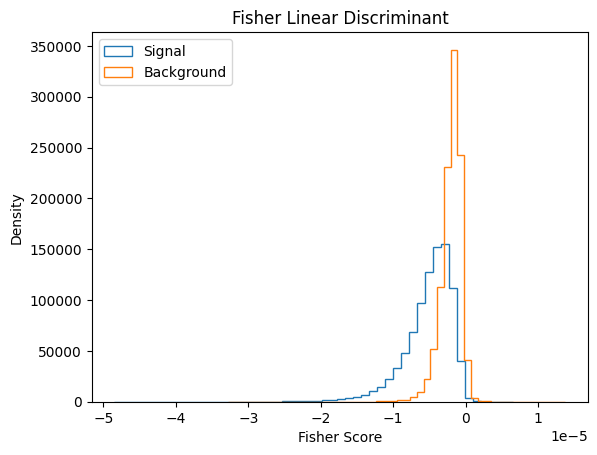

In [104]:
# Plotting the data to anayluze the reuslt 
plt.hist(signal_scores, bins = 50,
         histtype = "step", density = True,
         label = "Signal")

plt.hist(background_scores, bins = 50,
         histtype = "step", density = True,
         label = "Background")

plt.xlabel("Fisher Score")
plt.ylabel("Density")
plt.title("Fisher Linear Discriminant")

plt.legend()
plt.show()

In [105]:
# The ROC cuv eis very similar to 
# the one that was used earlier in 
# the lab

# I will be using that and use the 
# hinits that GPT gave me to do this
# Hee is what is happening , which 
# I need to replicate 

# I am going to compare the fisher socre to the cut
#culaute the signal count tha passes the TPR
# caulcaute the background count that passes the FPR
# and then plot the differnce 

# unfornulael, prior to this lab, I have
# not be able to effectly code thingd like this
# using GPT has helped me think throughh these problems 
# better . One thing i leaned that the 
# from the singla scores from the last part
# the shift was toward the left. This means
# the cut direction should be "<"

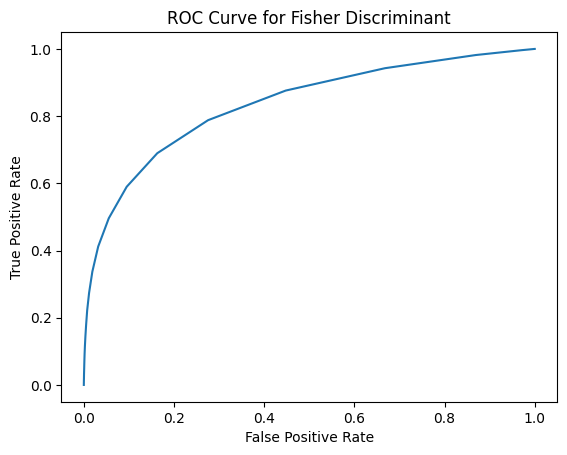

In [106]:
# Exercise 8.3

cuts = np.linspace(
    min(signal_scores.min(), background_scores.min()),
    max(signal_scores.max(), background_scores.max()),
    100
)

tpr = []
fpr = []

for cut in cuts:

    signal_passed = np.sum(signal_scores < cut)
    background_passed = np.sum(background_scores < cut)

    signal_eff = signal_passed / len(signal_scores)
    background_eff = background_passed / len(background_scores)

    tpr.append(signal_eff)
    fpr.append(background_eff)

plt.plot(fpr, tpr)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Fisher Discriminant")

plt.show()

The ROC curve shows how the True Positive changes Positive compared to the False Positive Rate as I change the Fisher score cut.

THe curve is above the diaognal, which means taht the selction is seperating the signal and the abckground better than the random selection. 

In [108]:
# Exercise 8.4
def fisher_significance(NS, NB):

    cuts = np.linspace(
        min(signal_scores.min(), background_scores.min()),
        max(signal_scores.max(), background_scores.max()),
        100
    )

    significance = []

    for cut in cuts:

        signal_passed = np.sum(signal_scores < cut)
        background_passed = np.sum(background_scores < cut)

        signal_eff = signal_passed / len(signal_scores)
        background_eff = background_passed / len(background_scores)

        new_signal = signal_eff * NS
        new_background = background_eff * NB

        if new_signal + new_background > 0:

            sigma = new_signal / np.sqrt(
                new_signal + new_background
            )

        else:

            sigma = 0

        significance.append(sigma)

    best_index = np.argmax(significance)

    best_cut = cuts[best_index]
    best_significance = significance[best_index]

    print("NS =", NS, "NB =", NB)
    print("Best Fisher cut:", best_cut)
    print("Maximum significance:", best_significance)
    print()

In [109]:
fisher_significance(10, 100)

fisher_significance(100, 1000)

fisher_significance(1000, 10000)

fisher_significance(10000, 100000)

NS = 10 NB = 100
Best Fisher cut: -4.4650229592812035e-06
Maximum significance: 1.5310381561574848

NS = 100 NB = 1000
Best Fisher cut: -4.4650229592812035e-06
Maximum significance: 4.841567758082201

NS = 1000 NB = 10000
Best Fisher cut: -4.4650229592812035e-06
Maximum significance: 15.310381561574848

NS = 10000 NB = 100000
Best Fisher cut: -4.4650229592812035e-06
Maximum significance: 48.41567758082201



What I learned: The maximum significances I found were about 1.531, 4.842, 15.310, and 48.416. These were slightly higher than the best significance values I found earlier using MET by itself. I also noticed that the best Fisher cut stayed the same for all four scenarios. On the coding side, I learned how to scan through many possible cut values, calculate the significance for each one, and use np.argmax(). 